In [1]:
from data_pipeline import prepare_pipeline
from dataset import create_dataloaders

# 1. Daten laden
train_df, val_df, test_df, feature_cols, scaler = prepare_pipeline()

# 2. DataLoader erstellen
batch_size = 64
train_loader, val_loader, test_loader = create_dataloaders(
    train_df, val_df, test_df, feature_cols, batch_size=batch_size
)

# 3. Shape-Check an einem Batch durchführen
x_hist, x_future, y_target = next(iter(train_loader))

print("\n=== DATALOADER SHAPE CHECK ===")
print(f"x_hist   Shape: {x_hist.shape}   --> (BatchSize, 48 Stunden, {x_hist.shape[2]} Features)")
print(f"x_future Shape: {x_future.shape} --> (BatchSize, 24 Stunden, {x_future.shape[2]} Features)")
print(f"y_target Shape: {y_target.shape} --> (BatchSize, 24 Stunden, 2 Targets: Solar & Wind)")

--> Lade Wetterdaten aus Cache...

[COVERAGE REPORT - Open-Meteo Weather API (Cache)]
  Angefragter Zeitraum: 2019-01-01 bis 2024-12-31 (52,608 Stunden)
  Erhaltene Datenpunkte: 52,608 / 52,608 Stunden (100.00% Abdeckung)
  ✓ Perfekt: Der Datensatz ist 100% lückenlos!
--------------------------------------------------
--> Lade bereinigte REALE SMARD-Daten aus Cache...

[COVERAGE REPORT - REALE SMARD-Daten (Cache)]
  Angefragter Zeitraum: 2019-01-01 bis 2024-12-31 (52,608 Stunden)
  Erhaltene Datenpunkte: 52,602 / 52,608 Stunden (99.99% Abdeckung)
  ⚠️  Fehlende Stunden: 6 Datenpunkte fehlen.
      Verteilung: Verteilt auf 6 einzelne Lücke(n)/Unterbrechung(en).
      Beispiel-Lücken:
        - Einzelausfall am 2019-03-31 02:00 UTC
        - Einzelausfall am 2020-03-29 02:00 UTC
        - Einzelausfall am 2021-03-28 02:00 UTC
        ... und 3 weitere Lücke(n).
--------------------------------------------------

=== PIPELINE STATUS ===
Features insgesamt (51): ['temperature_2m_NW', 'wind

In [2]:
from data_pipeline import prepare_pipeline
from dataset import create_dataloaders
from baselines import SeasonalPersistenceBaseline, RidgeRegressionBaseline, evaluate_metrics
import pandas as pd


print("\n" + "="*50)
print("EVALUATION DER BASELINE-MODELLE (VALIDATION-SET 2023)")
print("="*50)

# --- 2. Persistence Baseline ---
persistence_model = SeasonalPersistenceBaseline()
# Hier strikt val_loader nutzen!
y_pred_pers, y_true_pers = persistence_model.predict(val_loader)
metrics_pers = evaluate_metrics(y_true_pers, y_pred_pers)

# --- 3. Ridge Regression Baseline ---
ridge_model = RidgeRegressionBaseline(alpha=100.0)
ridge_model.fit(train_loader)
# Hier strikt val_loader nutzen!
y_pred_ridge, y_true_ridge = ridge_model.predict(val_loader)
metrics_ridge = evaluate_metrics(y_true_ridge, y_pred_ridge)

# --- 4. Ergebnisse auf dem Validation-Set zusammenfassen ---
results_data = {
    'Modell': ['Persistence (Naiv)', 'Ridge Regression (Linear)'],
    'Overall MAE': [metrics_pers['overall']['MAE'], metrics_ridge['overall']['MAE']],
    'Overall RMSE': [metrics_pers['overall']['RMSE'], metrics_ridge['overall']['RMSE']],
    'Solar MAE': [metrics_pers['solar']['MAE'], metrics_ridge['solar']['MAE']],
    'Solar RMSE': [metrics_pers['solar']['RMSE'], metrics_ridge['solar']['RMSE']],
    'Wind MAE': [metrics_pers['wind']['MAE'], metrics_ridge['wind']['MAE']],
    'Wind RMSE': [metrics_pers['wind']['RMSE'], metrics_ridge['wind']['RMSE']],
}

df_results_val = pd.DataFrame(results_data)
print("\n=== BASELINE RESULTATE (VALIDATION SET 2023) ===")
print(df_results_val.to_string(index=False))


EVALUATION DER BASELINE-MODELLE (VALIDATION-SET 2023)
--> Trainiere Ridge Regression Baseline...
✓ Ridge Regression erfolgreich trainiert.

=== BASELINE RESULTATE (VALIDATION SET 2023) ===
                   Modell  Overall MAE  Overall RMSE  Solar MAE  Solar RMSE  Wind MAE  Wind RMSE
       Persistence (Naiv)     0.063708      0.107410   0.019459    0.041354  0.107961   0.146168
Ridge Regression (Linear)     0.018235      0.026471   0.011066    0.018302  0.025408   0.032659



EXPERIMENT: LSTM MODEL
--> [CACHE HIT] Modell 'RecurrentForecaster_batch_size-64_cell-LSTM_dropout-0.1_hidden_dim-64_lr-0.001_num_layers-2_use_skip-True' existiert bereits. Lade Gewichte & Metadaten...

EXPERIMENT: GRU MODEL
--> [CACHE HIT] Modell 'RecurrentForecaster_batch_size-64_cell-GRU_dropout-0.1_hidden_dim-64_lr-0.001_num_layers-2_use_skip-True' existiert bereits. Lade Gewichte & Metadaten...


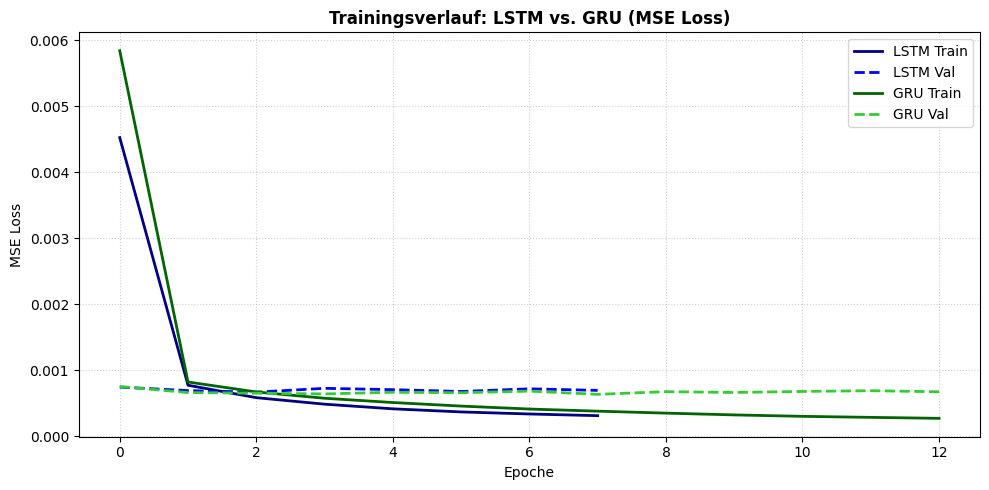


=== VERGLEICH DER RECURRENTEN MODELLE (VALIDATION SET 2023) ===
Modell Parameter  Lernzeit (s)  Overall MAE  Overall RMSE  Solar MAE  Wind MAE
  LSTM   130,754        180.95     0.017213      0.025885   0.011927  0.022498
   GRU    99,010        731.16     0.016194      0.025231   0.009644  0.022745


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from data_pipeline import prepare_pipeline
from dataset import create_dataloaders
from models import RecurrentForecaster
from trainer import ModelTrainer
from baselines import evaluate_metrics


hist_dim = len(feature_cols) + 2  # Input-Features (Wetter + Kalender) + 2 Target-Historien
future_dim = len(feature_cols)    # Zukunfts-Input (Wetterprognose + Kalender)

# =====================================================================
# 2. LSTM MODEL (TRAINING / CACHE LOAD)
# =====================================================================
print("\n" + "="*50)
print("EXPERIMENT: LSTM MODEL")
print("="*50)

lstm_params = {
    'cell': 'LSTM',
    'hidden_dim': 64,
    'num_layers': 2,
    'dropout': 0.1,
    'use_skip': True,
    'lr': 0.001,
    'batch_size': batch_size
}

lstm_model = RecurrentForecaster(
    hist_dim=hist_dim, 
    future_dim=future_dim, 
    cell_type=lstm_params['cell'], 
    hidden_dim=lstm_params['hidden_dim'],
    num_layers=lstm_params['num_layers'],
    dropout=lstm_params['dropout'],
    use_skip=lstm_params['use_skip']
)
lstm_trainer = ModelTrainer(lstm_model, lr=lstm_params['lr'])

# Automatisch laden falls existiert, sonst trainieren
lstm_meta = lstm_trainer.fit_or_load(
    train_loader, val_loader, hyperparams=lstm_params, epochs=25, patience=5
)
lstm_history = lstm_meta['history']

# Evaluieren auf Validation Set
_, y_pred_lstm, y_true_val = lstm_trainer.evaluate(val_loader)
metrics_lstm = evaluate_metrics(y_true_val, y_pred_lstm)


# =====================================================================
# 3. GRU MODEL (TRAINING / CACHE LOAD)
# =====================================================================
print("\n" + "="*50)
print("EXPERIMENT: GRU MODEL")
print("="*50)

gru_params = {
    'cell': 'GRU',
    'hidden_dim': 64,
    'num_layers': 2,
    'dropout': 0.1,
    'use_skip': True,
    'lr': 0.001,
    'batch_size': batch_size
}

gru_model = RecurrentForecaster(
    hist_dim=hist_dim, 
    future_dim=future_dim, 
    cell_type=gru_params['cell'], 
    hidden_dim=gru_params['hidden_dim'],
    num_layers=gru_params['num_layers'],
    dropout=gru_params['dropout'],
    use_skip=gru_params['use_skip']
)
gru_trainer = ModelTrainer(gru_model, lr=gru_params['lr'])

# Automatisch laden falls existiert, sonst trainieren
gru_meta = gru_trainer.fit_or_load(
    train_loader, val_loader, hyperparams=gru_params, epochs=25, patience=5
)
gru_history = gru_meta['history']

# Evaluieren auf Validation Set
_, y_pred_gru, _ = gru_trainer.evaluate(val_loader)
metrics_gru = evaluate_metrics(y_true_val, y_pred_gru)


# =====================================================================
# 4. GEMEINSAMER TRAININGSVERLAUF-PLOT
# =====================================================================
plt.figure(figsize=(10, 5))

# LSTM Kurven
plt.plot(lstm_history['train_loss'], label='LSTM Train', color='navy', linewidth=2)
plt.plot(lstm_history['val_loss'], label='LSTM Val', color='blue', linestyle='--', linewidth=2)

# GRU Kurven
plt.plot(gru_history['train_loss'], label='GRU Train', color='darkgreen', linewidth=2)
plt.plot(gru_history['val_loss'], label='GRU Val', color='limegreen', linestyle='--', linewidth=2)

plt.title("Trainingsverlauf: LSTM vs. GRU (MSE Loss)", fontweight='bold', fontsize=12)
plt.xlabel("Epoche", fontsize=10)
plt.ylabel("MSE Loss", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='upper right')

plt.tight_layout()
plt.show()

# =====================================================================
# 5. MODELLVERGLEICH TABELLE
# =====================================================================
comparison_data = {
    'Modell': ['LSTM', 'GRU'],
    'Parameter': [f"{lstm_meta['total_trainable_params']:,}", f"{gru_meta['total_trainable_params']:,}"],
    'Lernzeit (s)': [lstm_meta['training_time_seconds'], gru_meta['training_time_seconds']],
    'Overall MAE': [metrics_lstm['overall']['MAE'], metrics_gru['overall']['MAE']],
    'Overall RMSE': [metrics_lstm['overall']['RMSE'], metrics_gru['overall']['RMSE']],
    'Solar MAE': [metrics_lstm['solar']['MAE'], metrics_gru['solar']['MAE']],
    'Wind MAE': [metrics_lstm['wind']['MAE'], metrics_gru['wind']['MAE']]
}

df_comparison = pd.DataFrame(comparison_data)
print("\n=== VERGLEICH DER RECURRENTEN MODELLE (VALIDATION SET 2023) ===")
print(df_comparison.to_string(index=False))

--> Lade Wetterdaten aus Cache...

[COVERAGE REPORT - Open-Meteo Weather API (Cache)]
  Angefragter Zeitraum: 2019-01-01 bis 2024-12-31 (52,608 Stunden)
  Erhaltene Datenpunkte: 52,608 / 52,608 Stunden (100.00% Abdeckung)
  ✓ Perfekt: Der Datensatz ist 100% lückenlos!
--------------------------------------------------
--> Lade bereinigte REALE SMARD-Daten aus Cache...

[COVERAGE REPORT - REALE SMARD-Daten (Cache)]
  Angefragter Zeitraum: 2019-01-01 bis 2024-12-31 (52,608 Stunden)
  Erhaltene Datenpunkte: 52,602 / 52,608 Stunden (99.99% Abdeckung)
  ⚠️  Fehlende Stunden: 6 Datenpunkte fehlen.
      Verteilung: Verteilt auf 6 einzelne Lücke(n)/Unterbrechung(en).
      Beispiel-Lücken:
        - Einzelausfall am 2019-03-31 02:00 UTC
        - Einzelausfall am 2020-03-29 02:00 UTC
        - Einzelausfall am 2021-03-28 02:00 UTC
        ... und 3 weitere Lücke(n).
--------------------------------------------------

=== PIPELINE STATUS ===
Features insgesamt (51): ['temperature_2m_NW', 'wind

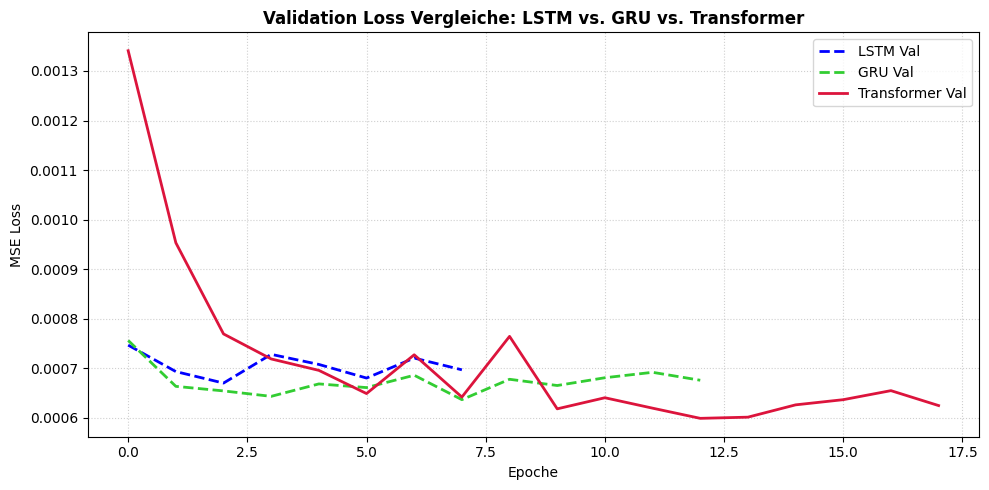


=== GESAMT-VERGLEICH ALLER DL-MODELLE (VALIDATION SET 2023) ===
              Modell Parameter  Lernzeit (s)  Overall MAE  Overall RMSE  Solar MAE  Wind MAE
                LSTM   130,754        180.95     0.017213      0.025885   0.011927  0.022498
                 GRU    99,010        731.16     0.016194      0.025231   0.009644  0.022745
Temporal Transformer   176,418       1741.68     0.015753      0.024473   0.009791  0.021716


In [3]:
from data_pipeline import prepare_pipeline
from dataset import create_dataloaders
from models import RecurrentForecaster, TemporalTransformer
from trainer import ModelTrainer
from baselines import evaluate_metrics
import matplotlib.pyplot as plt
import pandas as pd

# 1. Daten & DataLoader vorbereiten
train_df, val_df, test_df, feature_cols, scaler = prepare_pipeline()
batch_size = 64

train_loader, val_loader, test_loader = create_dataloaders(
    train_df, val_df, test_df, feature_cols, batch_size=batch_size
)

hist_dim = len(feature_cols) + 2
future_dim = len(feature_cols)

# =====================================================================
# 2. TEMPORAL TRANSFORMER MODEL (TRAINING / CACHE LOAD)
# =====================================================================
print("\n" + "="*50)
print("EXPERIMENT: TEMPORAL TRANSFORMER MODEL")
print("="*50)

tf_params = {
    'd_model': 64,
    'nhead': 4,
    'num_encoder_layers': 2,
    'num_decoder_layers': 2,
    'dim_feedforward': 128,
    'dropout': 0.1,
    'lr': 0.0005,  # Transformer mögen oft leicht kleineres LR als RNNs
    'batch_size': batch_size
}

tf_model = TemporalTransformer(
    hist_dim=hist_dim,
    future_dim=future_dim,
    d_model=tf_params['d_model'],
    nhead=tf_params['nhead'],
    num_encoder_layers=tf_params['num_encoder_layers'],
    num_decoder_layers=tf_params['num_decoder_layers'],
    dim_feedforward=tf_params['dim_feedforward'],
    dropout=tf_params['dropout']
)

tf_trainer = ModelTrainer(tf_model, lr=tf_params['lr'])

# Automatisch laden falls existiert, sonst trainieren
tf_meta = tf_trainer.fit_or_load(
    train_loader, val_loader, hyperparams=tf_params, epochs=25, patience=5
)
tf_history = tf_meta['history']

# Evaluieren auf Validation Set
_, y_pred_tf, y_true_val = tf_trainer.evaluate(val_loader)
metrics_tf = evaluate_metrics(y_true_val, y_pred_tf)


# =====================================================================
# 3. GEMEINSAMER VERLAUF-PLOT (LSTM vs. GRU vs. TRANSFORMER)
# =====================================================================
plt.figure(figsize=(10, 5))

# LSTM
plt.plot(lstm_history['val_loss'], label='LSTM Val', color='blue', linestyle='--', linewidth=2)

# GRU
plt.plot(gru_history['val_loss'], label='GRU Val', color='limegreen', linestyle='--', linewidth=2)

# Transformer
plt.plot(tf_history['val_loss'], label='Transformer Val', color='crimson', linestyle='-', linewidth=2)

plt.title("Validation Loss Vergleiche: LSTM vs. GRU vs. Transformer", fontweight='bold', fontsize=12)
plt.xlabel("Epoche", fontsize=10)
plt.ylabel("MSE Loss", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='upper right')

plt.tight_layout()
plt.show()


# =====================================================================
# 4. GESAMTTABELLE DER DEEP LEARNING MODELLE
# =====================================================================
dl_comparison_data = {
    'Modell': ['LSTM', 'GRU', 'Temporal Transformer'],
    'Parameter': [f"{lstm_meta['total_trainable_params']:,}", f"{gru_meta['total_trainable_params']:,}", f"{tf_meta['total_trainable_params']:,}"],
    'Lernzeit (s)': [lstm_meta['training_time_seconds'], gru_meta['training_time_seconds'], tf_meta['training_time_seconds']],
    'Overall MAE': [metrics_lstm['overall']['MAE'], metrics_gru['overall']['MAE'], metrics_tf['overall']['MAE']],
    'Overall RMSE': [metrics_lstm['overall']['RMSE'], metrics_gru['overall']['RMSE'], metrics_tf['overall']['RMSE']],
    'Solar MAE': [metrics_lstm['solar']['MAE'], metrics_gru['solar']['MAE'], metrics_tf['solar']['MAE']],
    'Wind MAE': [metrics_lstm['wind']['MAE'], metrics_gru['wind']['MAE'], metrics_tf['wind']['MAE']]
}

df_dl_comparison = pd.DataFrame(dl_comparison_data)
print("\n=== GESAMT-VERGLEICH ALLER DL-MODELLE (VALIDATION SET 2023) ===")
print(df_dl_comparison.to_string(index=False))

In [5]:
import pandas as pd
import itertools
from models import RecurrentForecaster, TemporalTransformer
from dataset import create_dataloaders
from trainer import ModelTrainer
from baselines import evaluate_metrics

def run_flexible_grid_search(model_type, param_grid, train_df, val_df, test_df, 
                             feature_cols, batch_size=64, epochs=20, patience=5):
    """
    Erweiterte Grid-Search Funktion, die auch dynamische lookback_hours (Dataset-Ebene)
    und num_layers (Modell-Ebene) unterstützt.
    """
    # 1. Alle Kombinationen generieren
    keys, values = zip(*param_grid.items())
    all_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]
    
    print(f"\n==================================================")
    print(f"START EXTENDED GRID SEARCH: {model_type} ({len(all_combinations)} Kombinationen)")
    print(f"==================================================")
    
    results = []
    current_lookback = None
    train_loader, val_loader = None, None
    
    for i, p in enumerate(all_combinations, 1):
        lookback = p.get('lookback_hours', 48)
        
        # 2. DataLoader nur NEU BAUEN, wenn sich lookback_hours geändert hat
        if lookback != current_lookback:
            print(f"\n--> erstelle DataLoader für lookback_hours = {lookback}h...")
            train_loader, val_loader, _ = create_dataloaders(
                train_df, val_df, test_df, feature_cols, 
                batch_size=batch_size, hist_steps=lookback, pred_steps=24
            )
            current_lookback = lookback
            
        hist_dim = len(feature_cols) + 2  # Input-Features + 2 Targets (Solar & Wind)
        future_dim = len(feature_cols)
        
        p_eval = p.copy()
        p_eval['batch_size'] = batch_size
        p_eval['cell'] = model_type
        
        # 3. Modell instanziieren
        if model_type in ['GRU', 'LSTM']:
            model = RecurrentForecaster(
                hist_dim=hist_dim, 
                future_dim=future_dim, 
                cell_type=model_type,
                hidden_dim=p.get('hidden_dim', 64), 
                num_layers=p.get('num_layers', 2), 
                dropout=p.get('dropout', 0.1), 
                use_skip=p.get('use_skip', True)
            )
        elif model_type == 'TRANSFORMER':
            model = TemporalTransformer(
                hist_dim=hist_dim,
                future_dim=future_dim,
                d_model=p.get('d_model', 64),
                nhead=p.get('nhead', 4),
                num_encoder_layers=p.get('num_encoder_layers', 2),
                num_decoder_layers=p.get('num_decoder_layers', 2),
                dim_feedforward=p.get('dim_feedforward', 128),
                dropout=p.get('dropout', 0.1)
            )

        trainer = ModelTrainer(model, lr=p.get('lr', 0.001))
        
        # 4. Fit or Load ausführen (Caching greift automatisch)
        meta = trainer.fit_or_load(
            train_loader, val_loader, hyperparams=p_eval, 
            epochs=epochs, patience=patience
        )
        
        # 5. Evaluation auf Validation Set
        _, y_pred, y_true = trainer.evaluate(val_loader)
        metrics = evaluate_metrics(y_true, y_pred)
        
        res_row = {
            'Model': model_type,
            'Val MSE': meta['best_val_loss'],
            'Overall MAE': metrics['overall']['MAE'],
            'Solar MAE': metrics['solar']['MAE'],
            'Wind MAE': metrics['wind']['MAE'],
            'Time (s)': meta['training_time_seconds']
        }
        res_row.update(p)
        results.append(res_row)

    df_results = pd.DataFrame(results).sort_values(by='Overall MAE')
    return df_results

In [8]:
# =====================================================================
# ERWEITERTES SUCHGITTER FÜR RECURRENT MODELS (LSTM & GRU)
# =====================================================================
recurrent_grid = {
    'lookback_hours': [24, 48, 72], # 1, 2 oder 3 Tage Historie
    'num_layers': [1, 2, 3],        # Modell-Tiefe
    'hidden_dim': [64,],    # Speicher-Kapazität
    'lr': [0.001,],          # Lernrate
    'dropout': [0.1,],     # Regularisierung
    'use_skip': [True, ]       # Feature-Durchreichung (Skip Connection)
}

# 1. Ausführung für LSTM
df_lstm_grid = run_flexible_grid_search(
    model_type='LSTM',
    param_grid=recurrent_grid,
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    feature_cols=feature_cols,
    batch_size=64,
    epochs=20,
    patience=5
)

print("\n=== TOP 5 LSTM KONFIGURATIONEN (VALIDATION SET 2023) ===")
print(df_lstm_grid.head(5).to_string(index=False))

# 2. Ausführung für GRU
df_gru_grid = run_flexible_grid_search(
    model_type='GRU',
    param_grid=recurrent_grid,
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    feature_cols=feature_cols,
    batch_size=64,
    epochs=20,
    patience=5
)

print("\n=== TOP 5 GRU KONFIGURATIONEN (VALIDATION SET 2023) ===")
print(df_gru_grid.head(5).to_string(index=False))


START EXTENDED GRID SEARCH: LSTM (9 Kombinationen)

--> erstelle DataLoader für lookback_hours = 24h...
--> [TRAINING START] Keinen Cache gefunden. Trainiere 'RecurrentForecaster_batch_size-64_cell-LSTM_dropout-0.1_hidden_dim-64_lookback_hours-24_lr-0.001_num_layers-1_use_skip-True'...
  Epoch 01/20 | Train Loss: 0.007652 | Val Loss: 0.000805
  Epoch 02/20 | Train Loss: 0.000953 | Val Loss: 0.000735
  Epoch 03/20 | Train Loss: 0.000747 | Val Loss: 0.000627
  Epoch 04/20 | Train Loss: 0.000628 | Val Loss: 0.000626
  Epoch 05/20 | Train Loss: 0.000554 | Val Loss: 0.000678
  Epoch 06/20 | Train Loss: 0.000498 | Val Loss: 0.000676
  Epoch 07/20 | Train Loss: 0.000453 | Val Loss: 0.000718
  Epoch 08/20 | Train Loss: 0.000414 | Val Loss: 0.000683
  Epoch 09/20 | Train Loss: 0.000381 | Val Loss: 0.000702
--> Early Stopping getriggert nach Epoche 9.
✓ Training in 95.92s beendet. Modell & Metadaten unter './saved_models/' gespeichert.
--> [TRAINING START] Keinen Cache gefunden. Trainiere 'Recu

In [9]:
# Empfohlenes fokussiertes Grid für Schritt 2:
step2_grid_lstm = {
    'lookback_hours': [24, ],
    'num_layers': [1],
    'hidden_dim': [32, 64, 128],  # Prüfen, ob mehr Modellkapazität bei 1 Layer hilft
    'lr': [0.001, 0.0005],
    'dropout': [0.0, 0.1, 0.2],
    'use_skip': [True, False]     # Absichern, wie stark der Skip-Bypass wirkt
}

step2_grid_gru = {
    'lookback_hours': [48],
    'num_layers': [2],
    'hidden_dim': [32, 64, 128],
    'lr': [0.001, 0.0005],
    'dropout': [0.0, 0.1, 0.2],
    'use_skip': [True, False]
}

# 1. Ausführung für LSTM
df_lstm_grid_step2 = run_flexible_grid_search(
    model_type='LSTM',
    param_grid=step2_grid_lstm,
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    feature_cols=feature_cols,
    batch_size=64,
    epochs=20,
    patience=5
)

print("\n=== TOP 5 LSTM KONFIGURATIONEN (VALIDATION SET 2023) ===")
print(df_lstm_grid_step2.head(5).to_string(index=False))

# 2. Ausführung für GRU
df_gru_grid_step2 = run_flexible_grid_search(
    model_type='GRU',
    param_grid=step2_grid_gru,
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    feature_cols=feature_cols,
    batch_size=64,
    epochs=20,
    patience=5
)

print("\n=== TOP 5 GRU KONFIGURATIONEN (VALIDATION SET 2023) ===")
print(df_gru_grid_step2.head(5).to_string(index=False))


START EXTENDED GRID SEARCH: LSTM (36 Kombinationen)

--> erstelle DataLoader für lookback_hours = 24h...
--> [TRAINING START] Keinen Cache gefunden. Trainiere 'RecurrentForecaster_batch_size-64_cell-LSTM_dropout-0.0_hidden_dim-32_lookback_hours-24_lr-0.001_num_layers-1_use_skip-True'...
  Epoch 01/20 | Train Loss: 0.010648 | Val Loss: 0.001015
  Epoch 02/20 | Train Loss: 0.000725 | Val Loss: 0.000857
  Epoch 03/20 | Train Loss: 0.000572 | Val Loss: 0.000742
  Epoch 04/20 | Train Loss: 0.000476 | Val Loss: 0.000698
  Epoch 05/20 | Train Loss: 0.000407 | Val Loss: 0.000699
  Epoch 06/20 | Train Loss: 0.000358 | Val Loss: 0.000687
  Epoch 07/20 | Train Loss: 0.000323 | Val Loss: 0.000685
  Epoch 08/20 | Train Loss: 0.000296 | Val Loss: 0.000672
  Epoch 09/20 | Train Loss: 0.000273 | Val Loss: 0.000678
  Epoch 10/20 | Train Loss: 0.000256 | Val Loss: 0.000683
  Epoch 11/20 | Train Loss: 0.000241 | Val Loss: 0.000691
  Epoch 12/20 | Train Loss: 0.000228 | Val Loss: 0.000696
  Epoch 13/20 |

In [10]:
# =====================================================================
# KORRIGIERTES SUCHGITTER FÜR TEMPORAL TRANSFORMER
# =====================================================================
transformer_grid = {
    'lookback_hours': [24, 48],        # 1, 2 oder 3 Tage Historie
    'd_model': [64],                  # Embedding-Dimension (64 oder 128)
    'nhead': [4],                          # 4 Attention Heads (64/4=16, 128/4=32)
    'num_encoder_layers': [1, 2],          # Encoder-Tiefe
    'num_decoder_layers': [1, 2],          # Decoder-Tiefe
    'dim_feedforward': [128],         # Feedforward Expansion
    'lr': [0.0005, 0.0001],                # Sanftere Lernraten
    'dropout': [0.1]
}

# Ausführung für Transformer
df_transformer_grid = run_flexible_grid_search(
    model_type='TRANSFORMER',
    param_grid=transformer_grid,
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    feature_cols=feature_cols,
    batch_size=64,
    epochs=20,
    patience=5
)

print("\n=== TOP 5 TRANSFORMER KONFIGURATIONEN (VALIDATION SET 2023) ===")
print(df_transformer_grid.head(5).to_string(index=False))


START EXTENDED GRID SEARCH: TRANSFORMER (16 Kombinationen)

--> erstelle DataLoader für lookback_hours = 24h...
--> [TRAINING START] Keinen Cache gefunden. Trainiere 'TemporalTransformer_batch_size-64_cell-TRANSFORMER_d_model-64_dim_feedforward-128_dropout-0.1_lookback_hours-24_lr-0.0005_nhead-4_num_decoder_layers-1_num_encoder_layers-1'...
  Epoch 01/20 | Train Loss: 0.006725 | Val Loss: 0.001331
  Epoch 02/20 | Train Loss: 0.001693 | Val Loss: 0.000856
  Epoch 03/20 | Train Loss: 0.001219 | Val Loss: 0.000781
  Epoch 04/20 | Train Loss: 0.000987 | Val Loss: 0.000692
  Epoch 05/20 | Train Loss: 0.000843 | Val Loss: 0.000660
  Epoch 06/20 | Train Loss: 0.000742 | Val Loss: 0.000686
  Epoch 07/20 | Train Loss: 0.000671 | Val Loss: 0.000650
  Epoch 08/20 | Train Loss: 0.000613 | Val Loss: 0.000639
  Epoch 09/20 | Train Loss: 0.000569 | Val Loss: 0.000664
  Epoch 10/20 | Train Loss: 0.000532 | Val Loss: 0.000684
  Epoch 11/20 | Train Loss: 0.000497 | Val Loss: 0.000656
  Epoch 12/20 | Tr

In [45]:
# =====================================================================
# KORRIGIERTES SUCHGITTER FÜR TEMPORAL TRANSFORMER
# =====================================================================
transformer_grid_step2 = {
    'lookback_hours': [48, 72],        # 1, 2 oder 3 Tage Historie
    'd_model': [128],                  # Embedding-Dimension (64 oder 128)
    'nhead': [4],                          # 4 Attention Heads (64/4=16, 128/4=32)
    'num_encoder_layers': [2],          # Encoder-Tiefe
    'num_decoder_layers': [2],          # Decoder-Tiefe
    'dim_feedforward': [256],         # Feedforward Expansion
    'lr': [0.0001],                # Sanftere Lernraten
    'dropout': [0.2]
}

# Ausführung für Transformer
df_transformer_grid_step2 = run_flexible_grid_search(
    model_type='TRANSFORMER',
    param_grid=transformer_grid_step2,
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    feature_cols=feature_cols,
    batch_size=64,
    epochs=50,
    patience=5
)

print("\n=== TOP 5 TRANSFORMER KONFIGURATIONEN (VALIDATION SET 2023) ===")
print(df_transformer_grid_step2.head(4).to_string(index=False))


START EXTENDED GRID SEARCH: TRANSFORMER (2 Kombinationen)

--> erstelle DataLoader für lookback_hours = 48h...
--> [TRAINING START] Keinen Cache gefunden. Trainiere 'TemporalTransformer_batch_size-64_cell-TRANSFORMER_d_model-128_dim_feedforward-256_dropout-0.2_lookback_hours-48_lr-0.0001_nhead-4_num_decoder_layers-2_num_encoder_layers-2'...
  Epoch 01/50 | Train Loss: 0.010609 | Val Loss: 0.002171
  Epoch 02/50 | Train Loss: 0.002895 | Val Loss: 0.001292
  Epoch 03/50 | Train Loss: 0.002010 | Val Loss: 0.000980
  Epoch 04/50 | Train Loss: 0.001573 | Val Loss: 0.000882
  Epoch 05/50 | Train Loss: 0.001307 | Val Loss: 0.000771
  Epoch 06/50 | Train Loss: 0.001138 | Val Loss: 0.000723
  Epoch 07/50 | Train Loss: 0.001017 | Val Loss: 0.000676
  Epoch 08/50 | Train Loss: 0.000928 | Val Loss: 0.000656
  Epoch 09/50 | Train Loss: 0.000857 | Val Loss: 0.000665
  Epoch 10/50 | Train Loss: 0.000794 | Val Loss: 0.000676
  Epoch 11/50 | Train Loss: 0.000738 | Val Loss: 0.000631
  Epoch 12/50 | Tr

In [ ]:
transformer_grid_step2 = {
    'lookback_hours': [48, 72],        # 1, 2 oder 3 Tage Historie
    'd_model': [64, 128],                  # Embedding-Dimension (64 oder 128)
    'nhead': [4],                          # 4 Attention Heads (64/4=16, 128/4=32)
    'num_encoder_layers': [2],          # Encoder-Tiefe
    'num_decoder_layers': [2],          # Decoder-Tiefe
    'dim_feedforward': [128, 256],         # Feedforward Expansion
    'lr': [0.0005, 0.0001],                # Sanftere Lernraten
    'dropout': [0.1,0.2]
}

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from data_pipeline import prepare_pipeline
from dataset import create_dataloaders
from baselines import evaluate_metrics, SeasonalPersistenceBaseline, RidgeRegressionBaseline
from models import RecurrentForecaster, TemporalTransformer
from trainer import ModelTrainer

# Matplotlib-Style konfigurieren
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# 1. Daten laden (Test-Set 2024)
train_df, val_df, test_df, feature_cols, scaler = prepare_pipeline()

# DataLoader für 24h und 48h Historie erstellen
train_loader_24, val_loader_24, test_loader_24 = create_dataloaders(
    train_df, val_df, test_df, feature_cols, batch_size=64, hist_steps=24, pred_steps=24
)
train_loader_48, val_loader_48, test_loader_48 = create_dataloaders(
    train_df, val_df, test_df, feature_cols, batch_size=64, hist_steps=48, pred_steps=24
)

hist_dim = len(feature_cols) + 2
future_dim = len(feature_cols)

# =====================================================================
# 2. HYPERPARAMETER DICTIONARIES (Exakt wie in run_flexible_grid_search)
# =====================================================================

# A. Bestes LSTM (24h Lookback)
lstm_params = {
    'batch_size': 64,
    'cell': 'LSTM',
    'dropout': 0.2,
    'hidden_dim': 128,
    'lookback_hours': 24,
    'lr': 0.0005,
    'num_layers': 1,
    'use_skip': True
}

# B. Beste GRU (48h Lookback)
gru_params = {
    'batch_size': 64,
    'cell': 'GRU',
    'dropout': 0.2,
    'hidden_dim': 128,
    'lookback_hours': 48,
    'lr': 0.0005,
    'num_layers': 2,
    'use_skip': False
}

# C. Temporal Transformer Gewinner (Step 2: 48h Lookback)
tf_params = {
    'batch_size': 64,
    'cell': 'TRANSFORMER',
    'd_model': 128,
    'dim_feedforward': 128,
    'dropout': 0.1,
    'lookback_hours': 48,
    'lr': 0.0005,
    'nhead': 4,
    'num_decoder_layers': 2,
    'num_encoder_layers': 2
}

# =====================================================================
# 3. BASELINES & DEEP LEARNING MODELLE LADEN / EVALUIEREN
# =====================================================================

# 1. Persistence Baseline
pers_model = SeasonalPersistenceBaseline()
y_pred_pers, y_true_test = pers_model.predict(test_loader_48)

# 2. Ridge Regression Baseline
# Zeitmessung starten
start_time = time.time()
ridge_model = RidgeRegressionBaseline(alpha=1.0)
ridge_model.fit(train_loader_48)
y_pred_ridge, _ = ridge_model.predict(test_loader_48)

# Zeitmessung stoppen
elapsed_time = time.time() - start_time

# Formatierte Ausgabe
print(f"⏱️ Ausführungszeit für Ridge Regression: {elapsed_time:.4f} Sekunden ({elapsed_time / 60:.2f} Minuten)")

# 3. Bestes LSTM
lstm_model = RecurrentForecaster(
    hist_dim=hist_dim,
    future_dim=future_dim,
    cell_type=lstm_params['cell'],
    hidden_dim=lstm_params['hidden_dim'],
    num_layers=lstm_params['num_layers'],
    dropout=lstm_params['dropout'],
    use_skip=lstm_params['use_skip']
)
lstm_trainer = ModelTrainer(lstm_model, lr=lstm_params['lr'])
lstm_meta = lstm_trainer.fit_or_load(train_loader_24, val_loader_24, hyperparams=lstm_params, epochs=20)
_, y_pred_lstm_raw, _ = lstm_trainer.evaluate(test_loader_24)
y_pred_lstm = y_pred_lstm_raw[24:]  # Auf 48h-Raster ausrichten

# 4. Beste GRU
gru_model = RecurrentForecaster(
    hist_dim=hist_dim,
    future_dim=future_dim,
    cell_type=gru_params['cell'],
    hidden_dim=gru_params['hidden_dim'],
    num_layers=gru_params['num_layers'],
    dropout=gru_params['dropout'],
    use_skip=gru_params['use_skip']
)
gru_trainer = ModelTrainer(gru_model, lr=gru_params['lr'])
gru_meta = gru_trainer.fit_or_load(train_loader_48, val_loader_48, hyperparams=gru_params, epochs=20)
_, y_pred_gru, _ = gru_trainer.evaluate(test_loader_48)

# 5. Temporal Transformer Gewinner
tf_model = TemporalTransformer(
    hist_dim=hist_dim,
    future_dim=future_dim,
    d_model=tf_params['d_model'],
    nhead=tf_params['nhead'],
    num_encoder_layers=tf_params['num_encoder_layers'],
    num_decoder_layers=tf_params['num_decoder_layers'],
    dim_feedforward=tf_params['dim_feedforward'],
    dropout=tf_params['dropout']
)
tf_trainer = ModelTrainer(tf_model, lr=tf_params['lr'])
tf_meta = tf_trainer.fit_or_load(train_loader_48, val_loader_48, hyperparams=tf_params, epochs=20)
_, y_pred_tf, _ = tf_trainer.evaluate(test_loader_48)

# =====================================================================
# 4. PREDICTIONS DICTIONARY FÜR DIE PLOTS
# =====================================================================

min_samples = min(len(y_true_test), len(y_pred_pers), len(y_pred_ridge), len(y_pred_lstm), len(y_pred_gru), len(y_pred_tf))

predictions = {
    'Ground Truth': y_true_test[:min_samples],
    'Persistence': y_pred_pers[:min_samples],
    'Ridge Regression': y_pred_ridge[:min_samples],
    'Bestes LSTM': y_pred_lstm[:min_samples],
    'Beste GRU': y_pred_gru[:min_samples],
    'Temporal Transformer': y_pred_tf[:min_samples]
}

color_map = {
    'Ground Truth': 'black',
    'Persistence': '#888888',
    'Ridge Regression': '#e67e22',
    'Bestes LSTM': '#2980b9',
    'Beste GRU': '#27ae60',
    'Temporal Transformer': '#c0392b'
}

style_map = {
    'Ground Truth': '-',
    'Persistence': ':',
    'Ridge Regression': '--',
    'Bestes LSTM': '-',
    'Beste GRU': '-',
    'Temporal Transformer': '-'
}

print("✅ Modell-Abruf erfolgreich! `fit_or_load` greift jetzt exakt auf die gecachten Checkpoints der Grid Search zu.")

--> Lade Wetterdaten aus Cache...

[COVERAGE REPORT - Open-Meteo Weather API (Cache)]
  Angefragter Zeitraum: 2019-01-01 bis 2024-12-31 (52,608 Stunden)
  Erhaltene Datenpunkte: 52,608 / 52,608 Stunden (100.00% Abdeckung)
  ✓ Perfekt: Der Datensatz ist 100% lückenlos!
--------------------------------------------------
--> Lade bereinigte REALE SMARD-Daten aus Cache...

[COVERAGE REPORT - REALE SMARD-Daten (Cache)]
  Angefragter Zeitraum: 2019-01-01 bis 2024-12-31 (52,608 Stunden)
  Erhaltene Datenpunkte: 52,602 / 52,608 Stunden (99.99% Abdeckung)
  ⚠️  Fehlende Stunden: 6 Datenpunkte fehlen.
      Verteilung: Verteilt auf 6 einzelne Lücke(n)/Unterbrechung(en).
      Beispiel-Lücken:
        - Einzelausfall am 2019-03-31 02:00 UTC
        - Einzelausfall am 2020-03-29 02:00 UTC
        - Einzelausfall am 2021-03-28 02:00 UTC
        ... und 3 weitere Lücke(n).
--------------------------------------------------

=== PIPELINE STATUS ===
Features insgesamt (51): ['temperature_2m_NW', 'wind

c:\Users\mgach\Documents\DeepLearningKurs-main\.venv_new\Lib\site-packages\sklearn\linear_model\_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=5.83921e-09): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


✓ Ridge Regression erfolgreich trainiert.
⏱️ Ausführungszeit für Ridge Regression: 5.0635 Sekunden (0.08 Minuten)
--> [CACHE HIT] Modell 'RecurrentForecaster_batch_size-64_cell-LSTM_dropout-0.2_hidden_dim-128_lookback_hours-24_lr-0.0005_num_layers-1_use_skip-True' existiert bereits. Lade Gewichte & Metadaten...
--> [CACHE HIT] Modell 'RecurrentForecaster_batch_size-64_cell-GRU_dropout-0.2_hidden_dim-128_lookback_hours-48_lr-0.0005_num_layers-2_use_skip-False' existiert bereits. Lade Gewichte & Metadaten...
--> [CACHE HIT] Modell 'TemporalTransformer_batch_size-64_cell-TRANSFORMER_d_model-128_dim_feedforward-128_dropout-0.1_lookback_hours-48_lr-0.0005_nhead-4_num_decoder_layers-2_num_encoder_layers-2' existiert bereits. Lade Gewichte & Metadaten...
✅ Modell-Abruf erfolgreich! `fit_or_load` greift jetzt exakt auf die gecachten Checkpoints der Grid Search zu.


## Train/Val Loss Verlauf mit Baseline-Linien

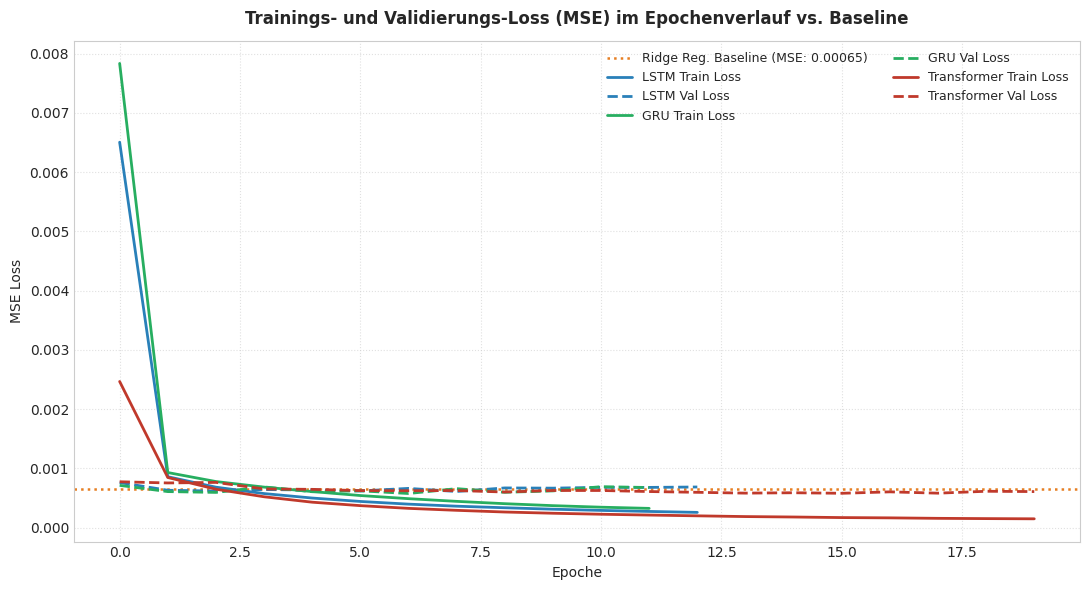

In [46]:
import matplotlib.pyplot as plt
from baselines import evaluate_metrics

plt.figure(figsize=(11, 6))

# Baseline-Referenzlinie (Ridge Regression)
ridge_mse = evaluate_metrics(y_true_test, y_pred_ridge)['overall']['MSE']
plt.axhline(
    y=ridge_mse, 
    color=color_map['Ridge Regression'], 
    linestyle=':', 
    linewidth=1.8, 
    label=f'Ridge Reg. Baseline (MSE: {ridge_mse:.5f})'
)

# 1. Bestes LSTM (Train vs. Val)
plt.plot(
    lstm_meta['history']['train_loss'], 
    label='LSTM Train Loss', 
    color=color_map['Bestes LSTM'], 
    linestyle='-', 
    linewidth=2
)
plt.plot(
    lstm_meta['history']['val_loss'], 
    label='LSTM Val Loss', 
    color=color_map['Bestes LSTM'], 
    linestyle='--', 
    linewidth=2
)

# 2. Beste GRU (Train vs. Val)
plt.plot(
    gru_meta['history']['train_loss'], 
    label='GRU Train Loss', 
    color=color_map['Beste GRU'], 
    linestyle='-', 
    linewidth=2
)
plt.plot(
    gru_meta['history']['val_loss'], 
    label='GRU Val Loss', 
    color=color_map['Beste GRU'], 
    linestyle='--', 
    linewidth=2
)

# 3. Temporal Transformer (Train vs. Val)
plt.plot(
    tf_meta['history']['train_loss'], 
    label='Transformer Train Loss', 
    color=color_map['Temporal Transformer'], 
    linestyle='-', 
    linewidth=2
)
plt.plot(
    tf_meta['history']['val_loss'], 
    label='Transformer Val Loss', 
    color=color_map['Temporal Transformer'], 
    linestyle='--', 
    linewidth=2
)

# Achsenbeschriftung und Layout
plt.title("Trainings- und Validierungs-Loss (MSE) im Epochenverlauf vs. Baseline", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Epoche", fontsize=10)
plt.ylabel("MSE Loss", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

# Legende in 2 Spalten für bessere Lesbarkeit
plt.legend(fontsize=9, loc='upper right', ncol=2)

plt.tight_layout()
plt.savefig("plot_01_training_val_history.png", dpi=300)
plt.show()

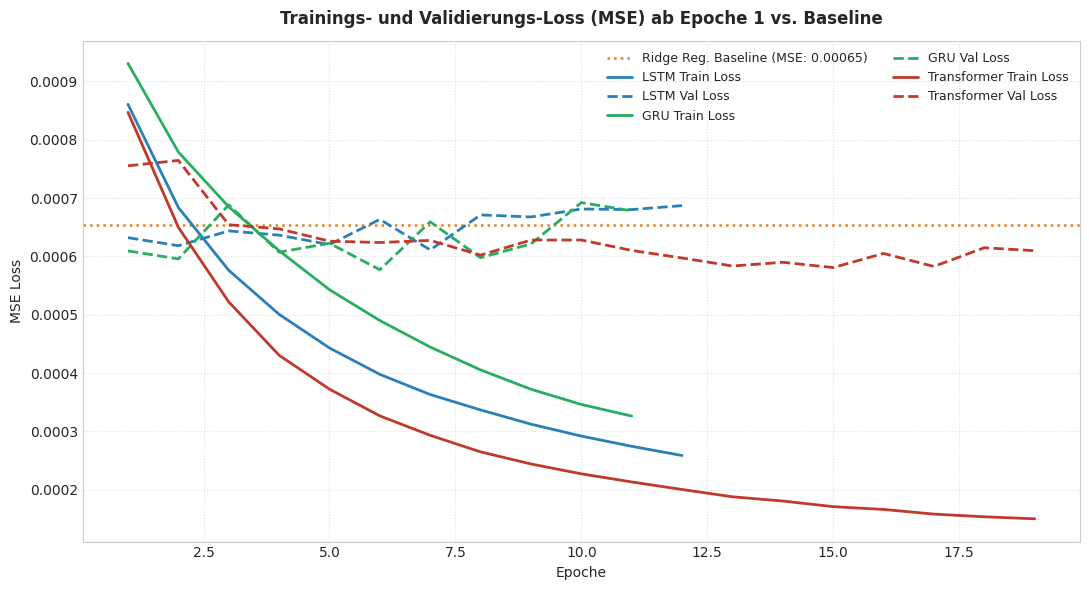

In [47]:
import matplotlib.pyplot as plt
from baselines import evaluate_metrics

plt.figure(figsize=(11, 6))

# Baseline-Referenzlinie (Ridge Regression)
ridge_mse = evaluate_metrics(y_true_test, y_pred_ridge)['overall']['MSE']
plt.axhline(
    y=ridge_mse, 
    color=color_map['Ridge Regression'], 
    linestyle=':', 
    linewidth=1.8, 
    label=f'Ridge Reg. Baseline (MSE: {ridge_mse:.5f})'
)

# Epochen-Indizes ab 1 erstellen (Länge der Historie minus Epoche 0)
epochs_lstm = range(1, len(lstm_meta['history']['train_loss']))
epochs_gru = range(1, len(gru_meta['history']['train_loss']))
epochs_tf = range(1, len(tf_meta['history']['train_loss']))

# 1. Bestes LSTM (ab Epoche 1)
plt.plot(
    epochs_lstm, lstm_meta['history']['train_loss'][1:], 
    label='LSTM Train Loss', color=color_map['Bestes LSTM'], linestyle='-', linewidth=2
)
plt.plot(
    epochs_lstm, lstm_meta['history']['val_loss'][1:], 
    label='LSTM Val Loss', color=color_map['Bestes LSTM'], linestyle='--', linewidth=2
)

# 2. Beste GRU (ab Epoche 1)
plt.plot(
    epochs_gru, gru_meta['history']['train_loss'][1:], 
    label='GRU Train Loss', color=color_map['Beste GRU'], linestyle='-', linewidth=2
)
plt.plot(
    epochs_gru, gru_meta['history']['val_loss'][1:], 
    label='GRU Val Loss', color=color_map['Beste GRU'], linestyle='--', linewidth=2
)

# 3. Temporal Transformer (ab Epoche 1)
plt.plot(
    epochs_tf, tf_meta['history']['train_loss'][1:], 
    label='Transformer Train Loss', color=color_map['Temporal Transformer'], linestyle='-', linewidth=2
)
plt.plot(
    epochs_tf, tf_meta['history']['val_loss'][1:], 
    label='Transformer Val Loss', color=color_map['Temporal Transformer'], linestyle='--', linewidth=2
)

# Achsenbeschriftung und Layout
plt.title("Trainings- und Validierungs-Loss (MSE) ab Epoche 1 vs. Baseline", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Epoche", fontsize=10)
plt.ylabel("MSE Loss", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

# Legende in 2 Spalten für bessere Lesbarkeit
plt.legend(fontsize=9, loc='upper right', ncol=2)

plt.tight_layout()
plt.savefig("plot_01_training_val_history_skip0.png", dpi=300)
plt.show()

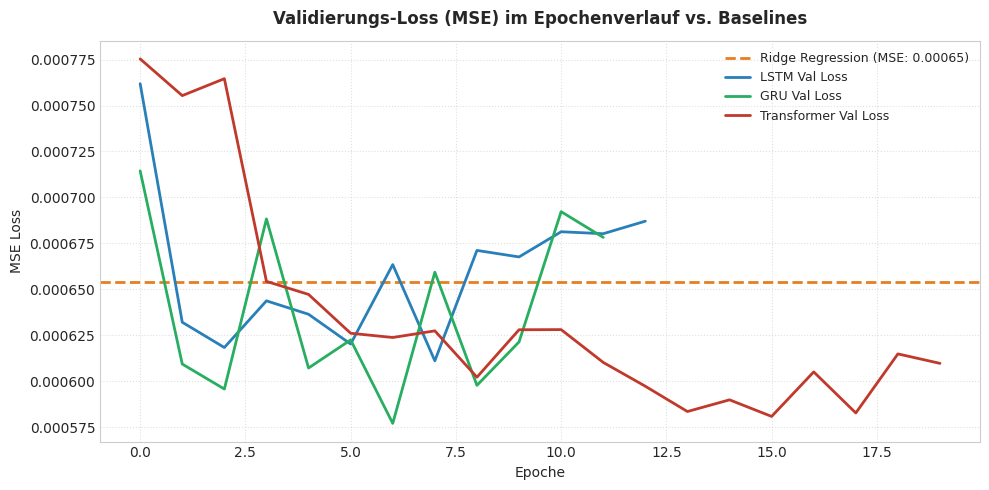

In [28]:
plt.figure(figsize=(10, 5))

# Baseline MAE/MSE Referenzlinien zeichnen
pers_mse = evaluate_metrics(y_true_test, y_pred_pers)['overall']['MSE']
ridge_mse = evaluate_metrics(y_true_test, y_pred_ridge)['overall']['MSE']

#plt.axhline(y=pers_mse, color=color_map['Persistence'], linestyle=style_map['Persistence'], linewidth=2, label=f'Persistence Baseline (MSE: {pers_mse:.5f})')
plt.axhline(y=ridge_mse, color=color_map['Ridge Regression'], linestyle=style_map['Ridge Regression'], linewidth=2, label=f'Ridge Regression (MSE: {ridge_mse:.5f})')

# Modell-Verläufe plottet
plt.plot(lstm_meta['history']['val_loss'], label='LSTM Val Loss', color=color_map['Bestes LSTM'], linewidth=2)
plt.plot(gru_meta['history']['val_loss'], label='GRU Val Loss', color=color_map['Beste GRU'], linewidth=2)
plt.plot(tf_meta['history']['val_loss'], label='Transformer Val Loss', color=color_map['Temporal Transformer'], linewidth=2)

plt.title("Validierungs-Loss (MSE) im Epochenverlauf vs. Baselines", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Epoche", fontsize=10)
plt.ylabel("MSE Loss", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=9, loc='upper right')
plt.tight_layout()

plt.savefig("plot_01_training_history.png", dpi=300)
plt.show()

## 24-Stunden Multi-Horizon Tagesszenarien

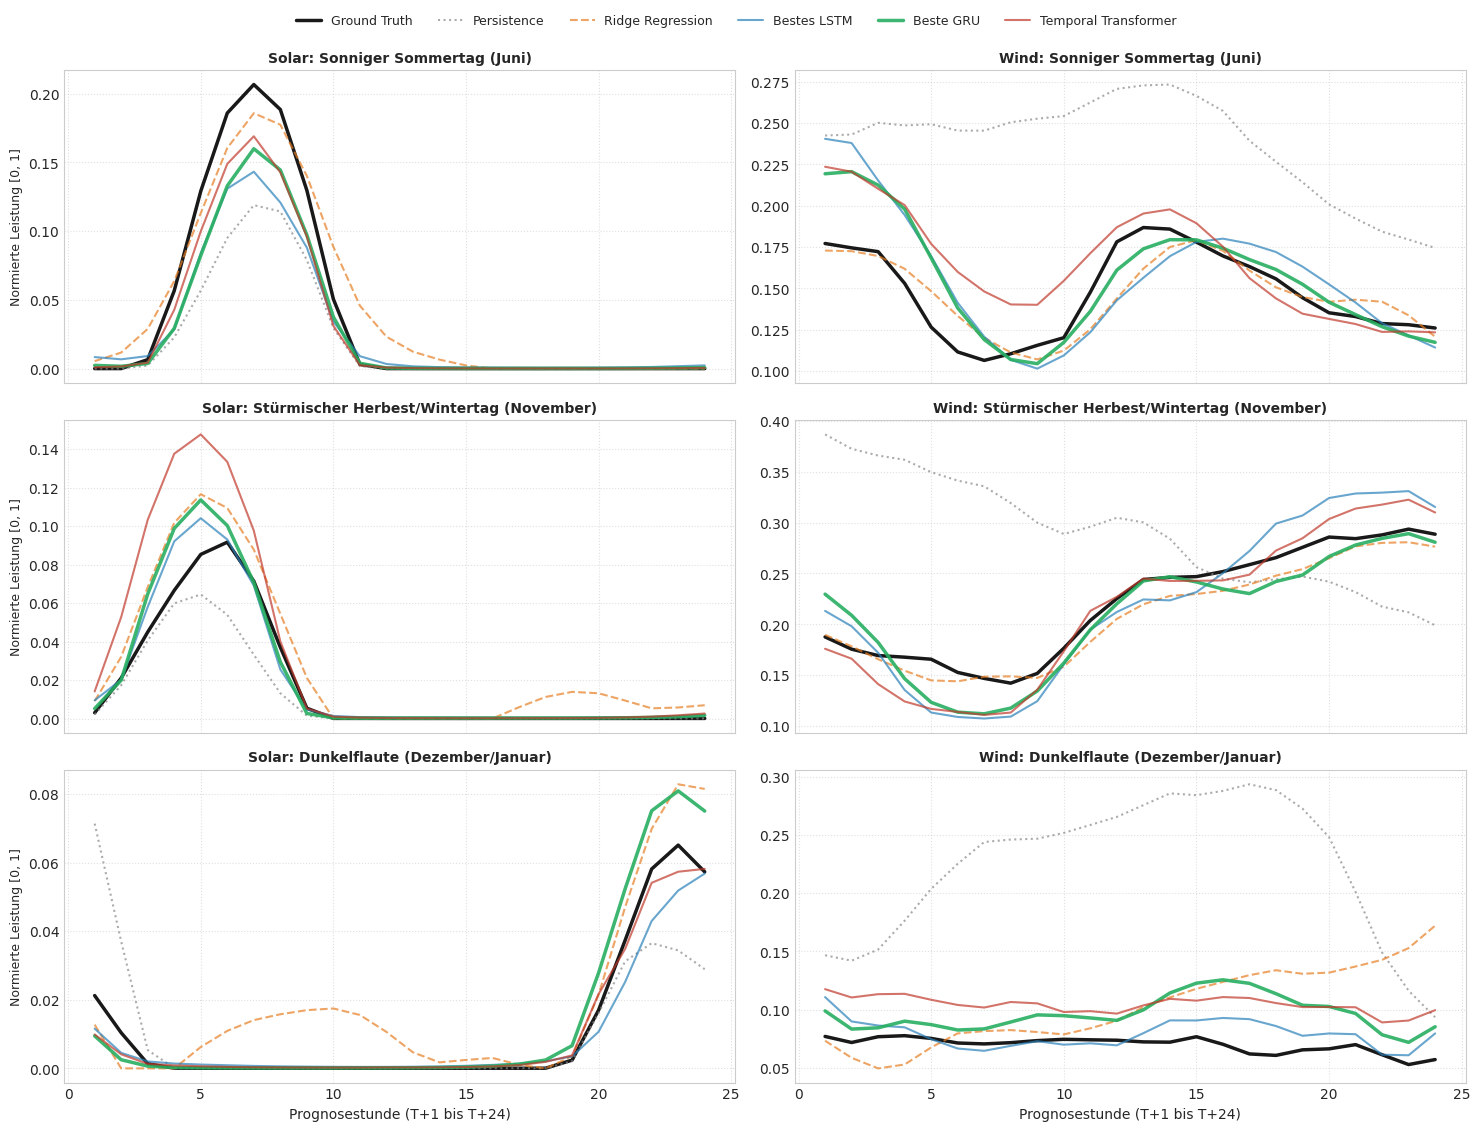

In [29]:
# Wir wählen 3 repräsentative Tage im Testjahr 2024 aus
# (Sample-Indizes anpassen, falls im Datensatz andere Tage liegen)
scenarios = {
    'Sonniger Sommertag (Juni)': 150,
    'Stürmischer Herbest/Wintertag (November)': 320,
    'Dunkelflaute (Dezember/Januar)': 350
}

fig, axes = plt.subplots(3, 2, figsize=(15, 11), sharex=True)
hours = np.arange(1, 25)

for row_idx, (scen_title, sample_idx) in enumerate(scenarios.items()):
    # Solar Plot (Spalte 0)
    ax_solar = axes[row_idx, 0]
    for model_name, y_pred in predictions.items():
        lw = 2.5 if model_name in ['Ground Truth', 'Beste GRU'] else 1.5
        alpha = 0.9 if model_name in ['Ground Truth', 'Beste GRU'] else 0.7
        ax_solar.plot(hours, y_pred[sample_idx, :, 0], label=model_name, 
                      color=color_map[model_name], linestyle=style_map[model_name], linewidth=lw, alpha=alpha)
    
    ax_solar.set_title(f"Solar: {scen_title}", fontweight='bold', fontsize=10)
    ax_solar.set_ylabel("Normierte Leistung [0, 1]", fontsize=9)
    ax_solar.grid(True, linestyle=':', alpha=0.6)
    
    # Wind Plot (Spalte 1)
    ax_wind = axes[row_idx, 1]
    for model_name, y_pred in predictions.items():
        lw = 2.5 if model_name in ['Ground Truth', 'Beste GRU'] else 1.5
        alpha = 0.9 if model_name in ['Ground Truth', 'Beste GRU'] else 0.7
        ax_wind.plot(hours, y_pred[sample_idx, :, 1], label=model_name, 
                     color=color_map[model_name], linestyle=style_map[model_name], linewidth=lw, alpha=alpha)
        
    ax_wind.set_title(f"Wind: {scen_title}", fontweight='bold', fontsize=10)
    ax_wind.grid(True, linestyle=':', alpha=0.6)

# Achsen-Beschriftung unten
axes[2, 0].set_xlabel("Prognosestunde (T+1 bis T+24)", fontsize=10)
axes[2, 1].set_xlabel("Prognosestunde (T+1 bis T+24)", fontsize=10)

# Gemeinsame Legende oben anzeigen
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.03), ncol=6, fontsize=9)

plt.tight_layout()
plt.savefig("plot_02_day_scenarios.png", dpi=300, bbox_inches='tight')
plt.show()

## Fehlerverlauf über den Prognosehorizont ($T+1$ bis $T+24$)

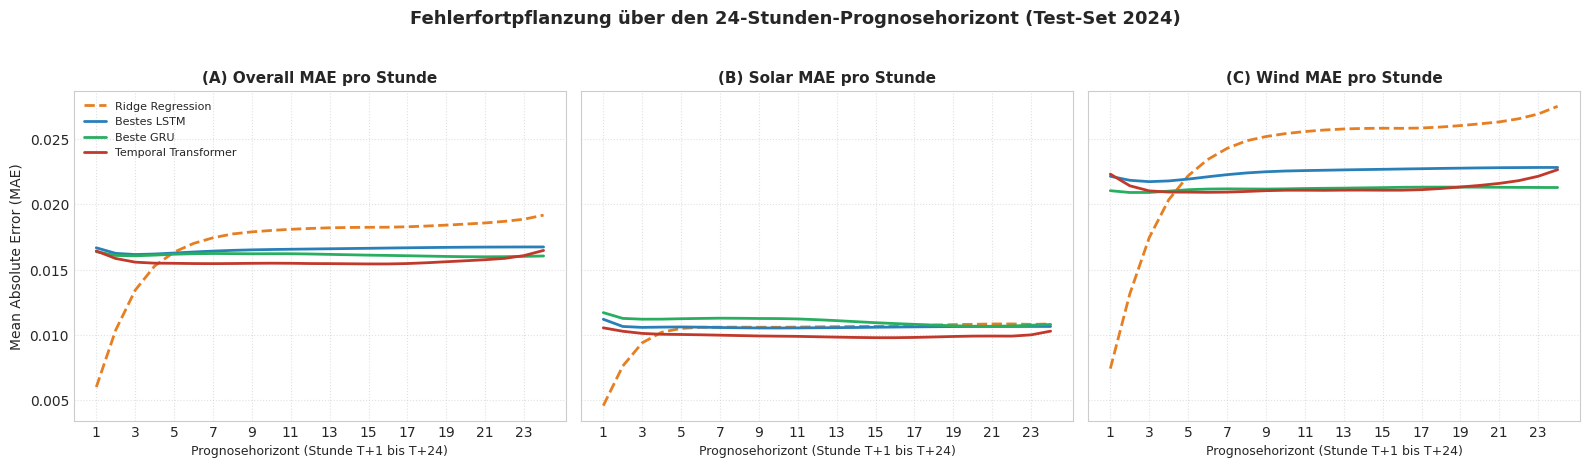

In [31]:
hours = np.arange(1, 25)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

models_to_plot = ['Ridge Regression', 'Bestes LSTM', 'Beste GRU', 'Temporal Transformer']

# Berechne MAE pro Stunde
for name in models_to_plot:
    y_p = predictions[name]
    abs_err = np.abs(y_p - y_true_test)
    
    mae_solar = abs_err[:, :, 0].mean(axis=0)
    mae_wind = abs_err[:, :, 1].mean(axis=0)
    mae_overall = abs_err.mean(axis=(0, 2))
    
    axes[0].plot(hours, mae_overall, label=name, color=color_map[name], linestyle=style_map[name], linewidth=2)
    axes[1].plot(hours, mae_solar, label=name, color=color_map[name], linestyle=style_map[name], linewidth=2)
    axes[2].plot(hours, mae_wind, label=name, color=color_map[name], linestyle=style_map[name], linewidth=2)

titles = ['(A) Overall MAE pro Stunde', '(B) Solar MAE pro Stunde', '(C) Wind MAE pro Stunde']
for i, ax in enumerate(axes):
    ax.set_title(titles[i], fontweight='bold', fontsize=11)
    ax.set_xlabel("Prognosehorizont (Stunde T+1 bis T+24)", fontsize=9)
    ax.set_xticks(range(1, 25, 2))
    ax.grid(True, linestyle=':', alpha=0.6)
    if i == 0:
        ax.set_ylabel("Mean Absolute Error (MAE)", fontsize=10)
        ax.legend(fontsize=8, loc='upper left')

plt.suptitle("Fehlerfortpflanzung über den 24-Stunden-Prognosehorizont (Test-Set 2024)", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig("plot_03_horizon_error.png", dpi=300, bbox_inches='tight')
plt.show()

## Residual- / Fehlerverteilung (Histogramm & KDE)

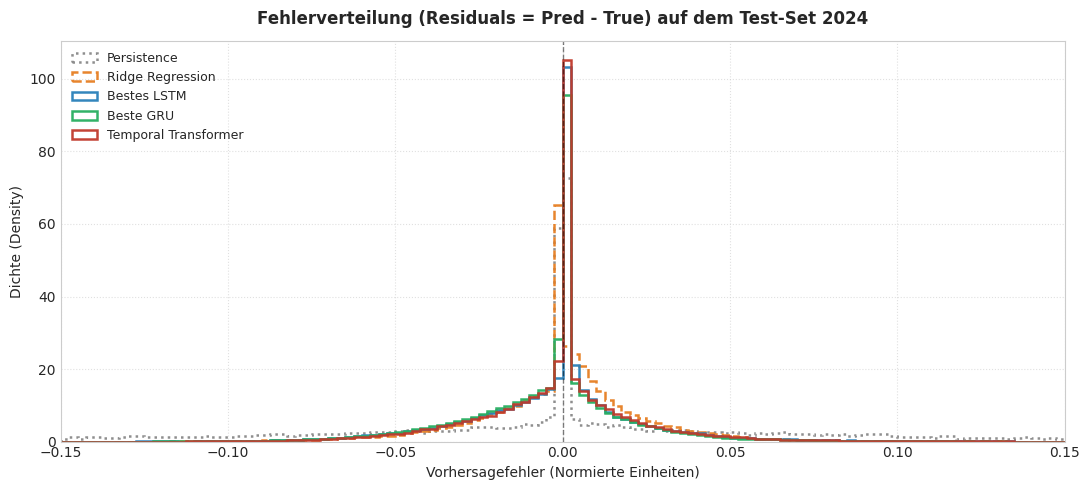

In [32]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

models_to_plot = ['Persistence', 'Ridge Regression', 'Bestes LSTM', 'Beste GRU', 'Temporal Transformer']

for name in models_to_plot:
    residuals = (predictions[name] - y_true_test).flatten()
    
    # Histogramm als Dichte-Linie (step) plotten
    plt.hist(residuals, bins=120, range=(-0.15, 0.15), density=True, 
             histtype='step', label=name, color=color_map[name], 
             linestyle=style_map[name], linewidth=1.8, alpha=0.95)

plt.axvline(x=0, color='black', linestyle='--', alpha=0.5, linewidth=1)
plt.xlim(-0.15, 0.15)
plt.title("Fehlerverteilung (Residuals = Pred - True) auf dem Test-Set 2024", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Vorhersagefehler (Normierte Einheiten)", fontsize=10)
plt.ylabel("Dichte (Density)", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=9, loc='upper left')

plt.tight_layout()
plt.savefig("plot_04_residuals_distribution.png", dpi=300)
plt.show()

## Balkendiagramm Erzeuger-Metriken (Solar vs. Wind MAE)

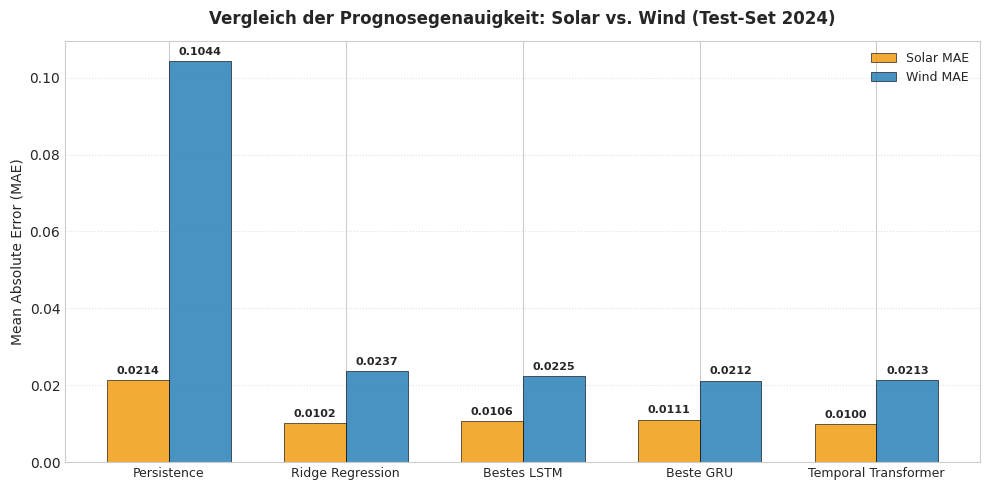

In [33]:
# Vorbereiten der Daten für das Gruppen-Balkendiagramm
models_order = ['Persistence', 'Ridge Regression', 'Bestes LSTM', 'Beste GRU', 'Temporal Transformer']

solar_maes = []
wind_maes = []

for name in models_order:
    m = evaluate_metrics(y_true_test, predictions[name])
    solar_maes.append(m['solar']['MAE'])
    wind_maes.append(m['wind']['MAE'])

x = np.arange(len(models_order))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

rects1 = ax.bar(x - width/2, solar_maes, width, label='Solar MAE', color='#f39c12', alpha=0.85, edgecolor='black', linewidth=0.5)
rects2 = ax.bar(x + width/2, wind_maes, width, label='Wind MAE', color='#2980b9', alpha=0.85, edgecolor='black', linewidth=0.5)

# Werte über den Balken anzeigen
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3pt vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

ax.set_title("Vergleich der Prognosegenauigkeit: Solar vs. Wind (Test-Set 2024)", fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel("Mean Absolute Error (MAE)", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(models_order, fontsize=9)
ax.legend(fontsize=9, loc='upper right')
ax.grid(True, axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("plot_05_solar_vs_wind_bar.png", dpi=300)
plt.show()

## Die Seasonal Heatmap

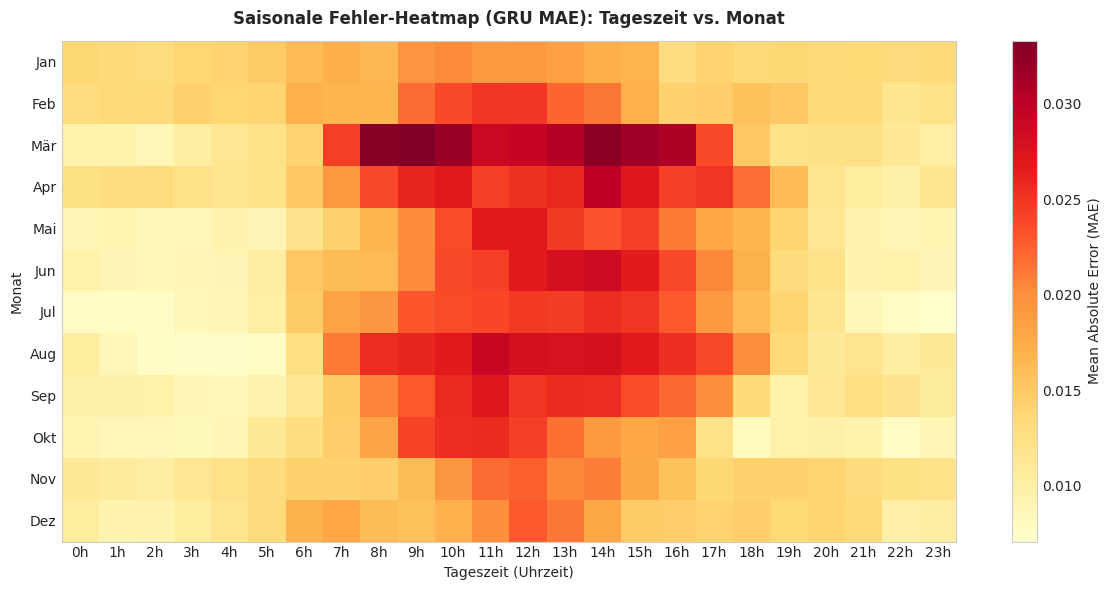

In [34]:
# ZELLE: Saisonale Fehler-Heatmap (Matplotlib-native)
import numpy as np
import matplotlib.pyplot as plt

# Fehler pro Zeitschritt berechnen
abs_err_gru = np.abs(predictions['Beste GRU'] - y_true_test).mean(axis=-1) # (N, 24)

# Zeitstempel aus dem Test-Set nutzen
timestamps = test_df.index[:len(abs_err_gru)]
months = timestamps.month
hours = timestamps.hour

heatmap_data = np.zeros((12, 24))
counts = np.zeros((12, 24))

for i in range(len(abs_err_gru)):
    m = months[i] - 1
    h = hours[i]
    heatmap_data[m, h] += abs_err_gru[i, 0] # Fehler der 1. Prognosestunde
    counts[m, h] += 1

heatmap_avg = heatmap_data / np.maximum(counts, 1)

plt.figure(figsize=(12, 6))
im = plt.imshow(heatmap_avg, cmap='YlOrRd', aspect='auto', origin='upper')

# Farb-Skala / Colorbar hinzufügen
cbar = plt.colorbar(im)
cbar.set_label('Mean Absolute Error (MAE)', fontsize=10)

plt.title("Saisonale Fehler-Heatmap (GRU MAE): Tageszeit vs. Monat", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Tageszeit (Uhrzeit)", fontsize=10)
plt.ylabel("Monat", fontsize=10)

plt.xticks(ticks=np.arange(24), labels=[f"{h}h" for h in range(24)])
plt.yticks(ticks=np.arange(12), labels=['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun', 'Jul', 'Aug', 'Sep', 'Okt', 'Nov', 'Dez'])
plt.grid(False) # Bei Imshow kein Grid nötig

plt.tight_layout()
plt.savefig("plot_06_seasonal_heatmap.png", dpi=300)
plt.show()

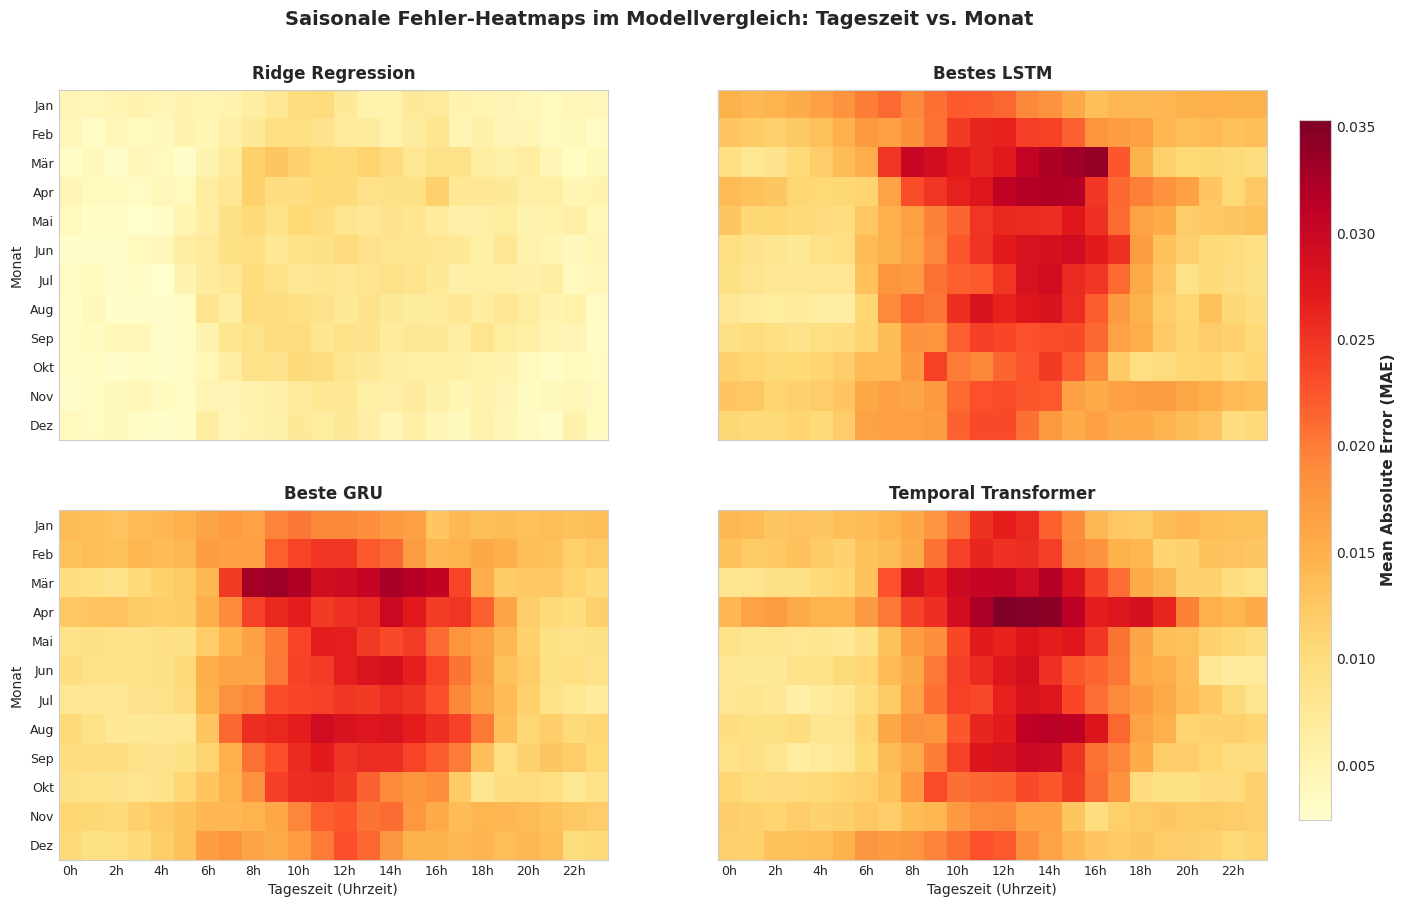

In [48]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup: 2x2 Grid erstellen
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
axes_flat = axes.flatten()

models_to_plot = ['Ridge Regression', 'Bestes LSTM', 'Beste GRU', 'Temporal Transformer']
month_labels = ['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun', 'Jul', 'Aug', 'Sep', 'Okt', 'Nov', 'Dez']

# Zeitstempel aus dem Test-Set (passend zur Länge der Vorhersagen)
sample_len = len(predictions['Beste GRU'])
timestamps = test_df.index[:sample_len]
months = timestamps.month.to_numpy()
hours = timestamps.hour.to_numpy()

# Vorbereiten der Matrix-Daten für alle 4 Modelle
heatmaps = {}
for name in models_to_plot:
    # Absoluter Fehler der 1. Prognosestunde über Solar und Wind gemsittelt
    abs_err = np.abs(predictions[name][:sample_len] - y_true_test[:sample_len]).mean(axis=-1)
    
    h_data = np.zeros((12, 24))
    counts = np.zeros((12, 24))
    
    for i in range(sample_len):
        m = months[i] - 1
        h = hours[i]
        h_data[m, h] += abs_err[i, 0] # Fehler der 1. Prognosestunde
        counts[m, h] += 1
        
    heatmaps[name] = h_data / np.maximum(counts, 1)

# Gemeinsame Min/Max-Werte für einheitliche Farbskala ermitteln
vmin = min([h.min() for h in heatmaps.values()])
vmax = max([h.max() for h in heatmaps.values()])

# 2. Plot-Schleife für das 2x2 Raster
images = []
for idx, name in enumerate(models_to_plot):
    ax = axes_flat[idx]
    im = ax.imshow(heatmaps[name], cmap='YlOrRd', aspect='auto', origin='upper', vmin=vmin, vmax=vmax)
    images.append(im)
    
    ax.set_title(f"{name}", fontsize=12, fontweight='bold', pad=8)
    ax.set_xticks(np.arange(0, 24, 2))
    ax.set_xticklabels([f"{h}h" for h in range(0, 24, 2)], fontsize=9)
    ax.set_yticks(np.arange(12))
    ax.set_yticklabels(month_labels, fontsize=9)
    ax.grid(False)
    
    if idx % 2 == 0:
        ax.set_ylabel("Monat", fontsize=10)
    if idx >= 2:
        ax.set_xlabel("Tageszeit (Uhrzeit)", fontsize=10)

# 3. Gemeinsame Colorbar rechts anfügen
fig.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(images[0], cax=cbar_ax)
cbar.set_label('Mean Absolute Error (MAE)', fontsize=11, fontweight='bold')

plt.suptitle("Saisonale Fehler-Heatmaps im Modellvergleich: Tageszeit vs. Monat", fontsize=14, fontweight='bold', y=0.96)
plt.savefig("plot_06_seasonal_heatmap_2x2.png", dpi=300, bbox_inches='tight')
plt.show()

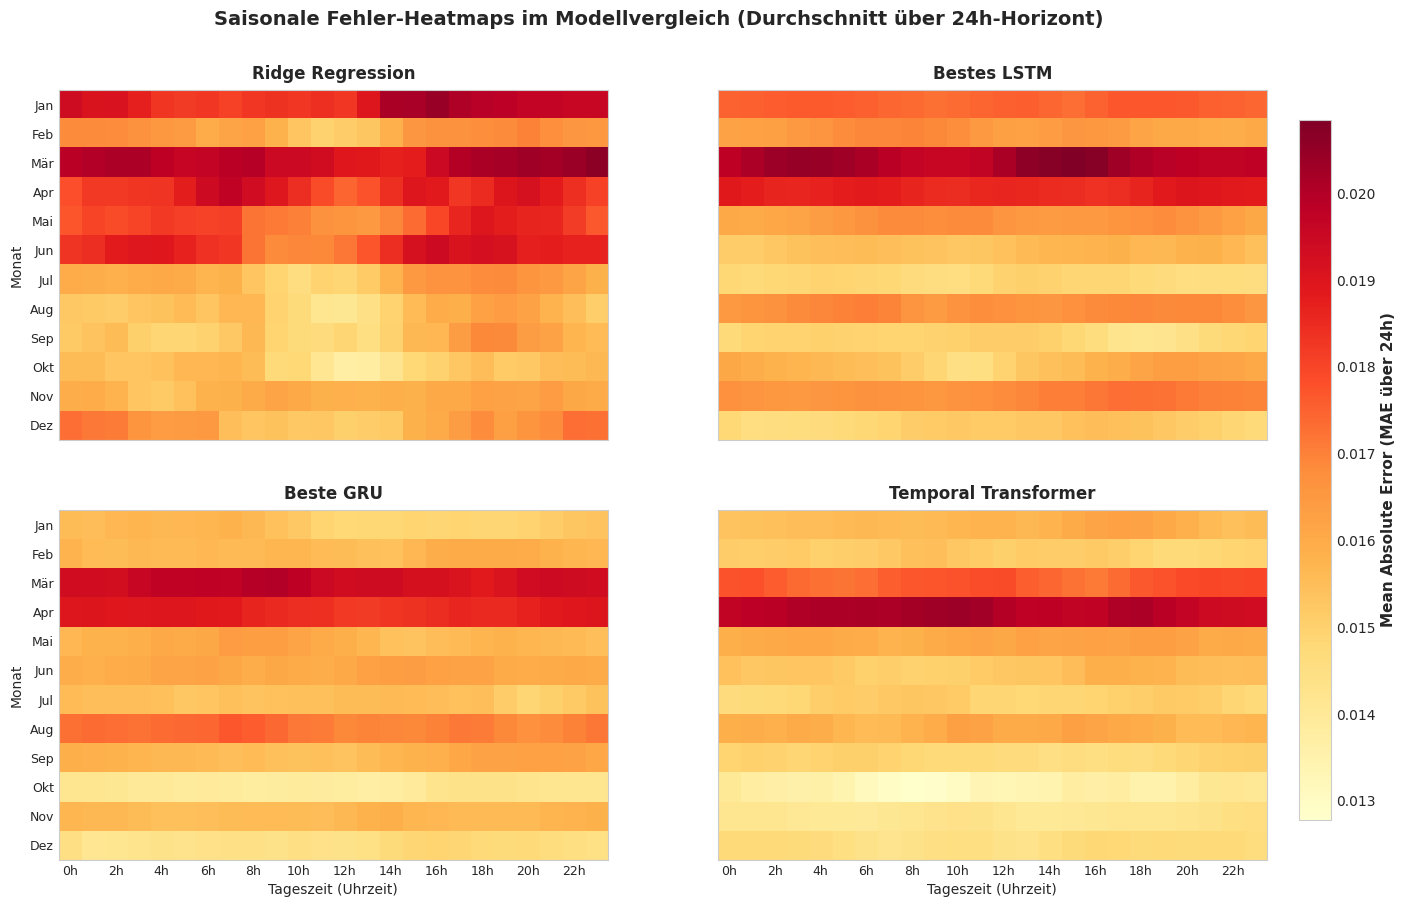

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup: 2x2 Grid erstellen
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
axes_flat = axes.flatten()

models_to_plot = ['Ridge Regression', 'Bestes LSTM', 'Beste GRU', 'Temporal Transformer']
month_labels = ['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun', 'Jul', 'Aug', 'Sep', 'Okt', 'Nov', 'Dez']

# Zeitstempel aus dem Test-Set
sample_len = len(predictions['Beste GRU'])
timestamps = test_df.index[:sample_len]
months = timestamps.month.to_numpy()
hours = timestamps.hour.to_numpy()

# Vorbereiten der Matrix-Daten für alle 4 Modelle
heatmaps = {}
for name in models_to_plot:
    # KORREKTUR: Wir mitteln über Target (axis=-1) UND über alle 24 Prognosestunden (axis=1)
    # Resultat: Array der Form (N,) -> Der durchschnittliche Tagesfehler des Samples i
    abs_err_24h = np.abs(predictions[name][:sample_len] - y_true_test[:sample_len]).mean(axis=(1, 2))
    
    h_data = np.zeros((12, 24))
    counts = np.zeros((12, 24))
    
    for i in range(sample_len):
        m = months[i] - 1
        h = hours[i]
        h_data[m, h] += abs_err_24h[i]  # KORREKTUR: Gesamter 24h-Mittelwert des Samples
        counts[m, h] += 1
        
    heatmaps[name] = h_data / np.maximum(counts, 1)

# Gemeinsame Min/Max-Werte für einheitliche Farbskala ermitteln
vmin = min([h.min() for h in heatmaps.values()])
vmax = max([h.max() for h in heatmaps.values()])

# 2. Plot-Schleife für das 2x2 Raster
images = []
for idx, name in enumerate(models_to_plot):
    ax = axes_flat[idx]
    im = ax.imshow(heatmaps[name], cmap='YlOrRd', aspect='auto', origin='upper', vmin=vmin, vmax=vmax)
    images.append(im)
    
    ax.set_title(f"{name}", fontsize=12, fontweight='bold', pad=8)
    ax.set_xticks(np.arange(0, 24, 2))
    ax.set_xticklabels([f"{h}h" for h in range(0, 24, 2)], fontsize=9)
    ax.set_yticks(np.arange(12))
    ax.set_yticklabels(month_labels, fontsize=9)
    ax.grid(False)
    
    if idx % 2 == 0:
        ax.set_ylabel("Monat", fontsize=10)
    if idx >= 2:
        ax.set_xlabel("Tageszeit (Uhrzeit)", fontsize=10)

# 3. Gemeinsame Colorbar rechts anfügen
fig.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(images[0], cax=cbar_ax)
cbar.set_label('Mean Absolute Error (MAE über 24h)', fontsize=11, fontweight='bold')

plt.suptitle("Saisonale Fehler-Heatmaps im Modellvergleich (Durchschnitt über 24h-Horizont)", fontsize=14, fontweight='bold', y=0.96)
plt.savefig("plot_06_seasonal_heatmap_2x2_correct24h.png", dpi=300, bbox_inches='tight')
plt.show()

## Scatter-Plot: Actual vs. Predicted (Paritäts-Diagramm)

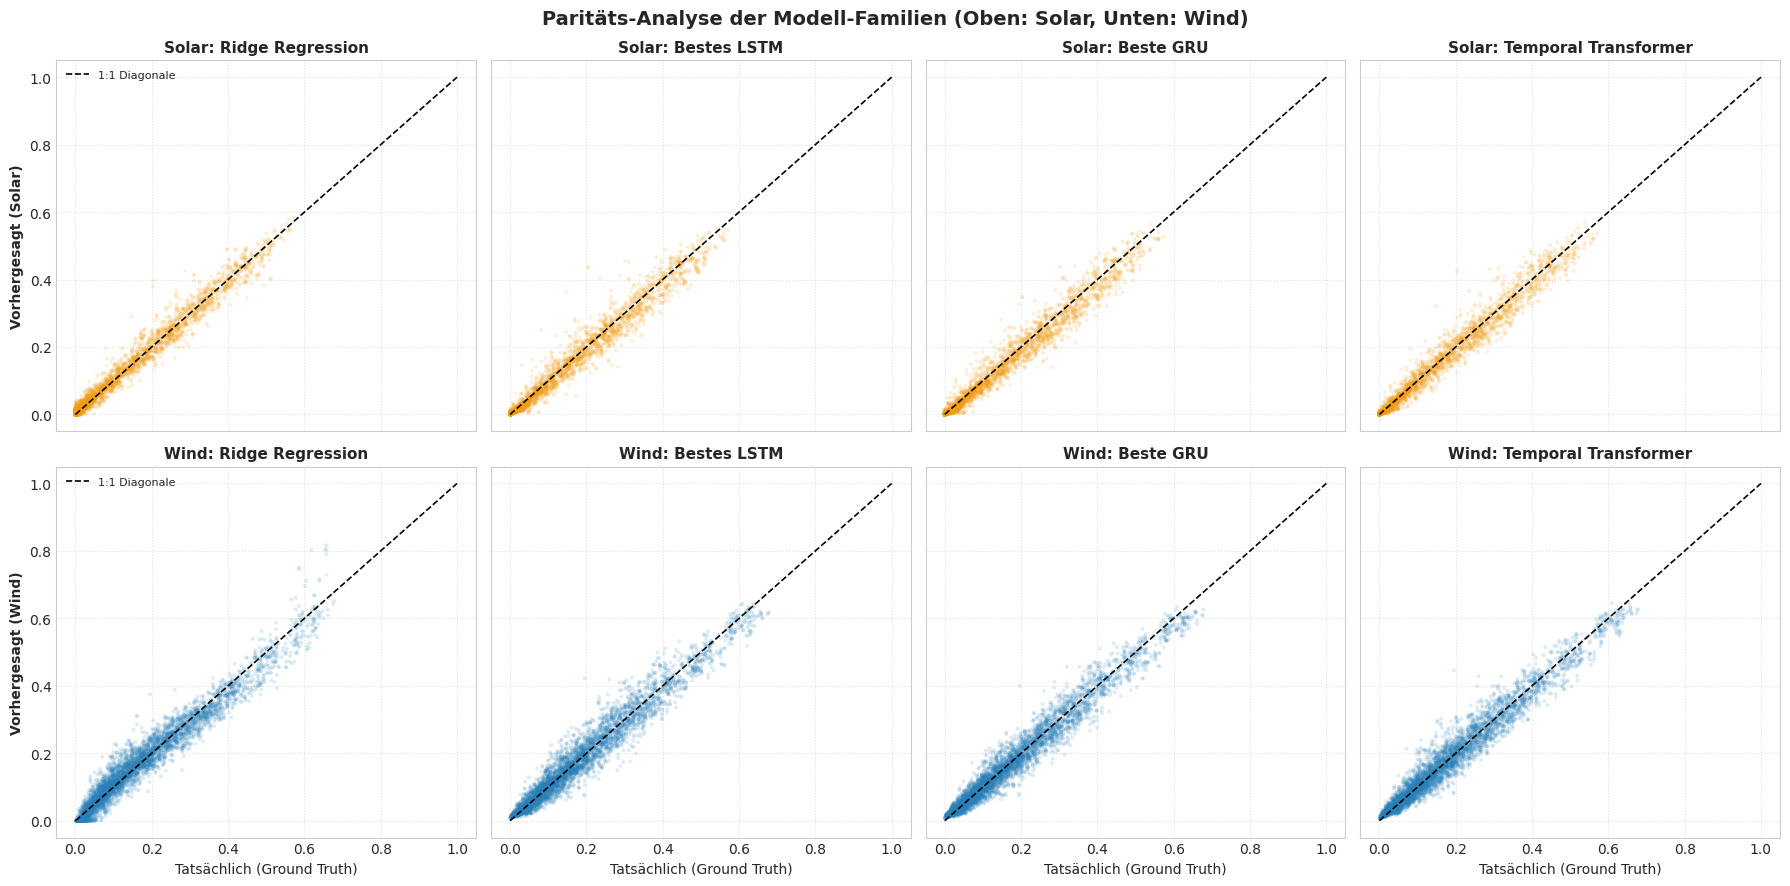

In [38]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Figure mit 2 Zeilen (Zeile 0: Solar, Zeile 1: Wind) und 4 Spalten (Modelle)
fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharex=True, sharey=True)

# Modelle ohne Persistence auswählen
models_to_plot = ['Ridge Regression', 'Bestes LSTM', 'Beste GRU', 'Temporal Transformer']

# Subsampling der Testdaten (gleicher Index-Identifikator für alle Modelle)
y_t_flat = y_true_test.reshape(-1, 2)
np.random.seed(42)
idx = np.random.choice(len(y_t_flat), size=5000, replace=False)

# 2. Schleife über alle 4 Modelle (Spalten 0 bis 3)
for col_idx, model_name in enumerate(models_to_plot):
    y_p_flat = predictions[model_name].reshape(-1, 2)
    
    # --- ZEILE 0: SOLAR (Target 0) ---
    ax_solar = axes[0, col_idx]
    ax_solar.scatter(y_t_flat[idx, 0], y_p_flat[idx, 0], alpha=0.15, color='#f39c12', s=8, edgecolors='none')
    ax_solar.plot([0, 1], [0, 1], 'k--', linewidth=1.2, label='1:1 Diagonale')
    ax_solar.set_title(f"Solar: {model_name}", fontweight='bold', fontsize=11)
    ax_solar.grid(True, linestyle=':', alpha=0.6)
    
    if col_idx == 0:
        ax_solar.set_ylabel("Vorhergesagt (Solar)", fontsize=10, fontweight='bold')
        ax_solar.legend(fontsize=8, loc='upper left')

    # --- ZEILE 1: WIND (Target 1) ---
    ax_wind = axes[1, col_idx]
    ax_wind.scatter(y_t_flat[idx, 1], y_p_flat[idx, 1], alpha=0.15, color='#2980b9', s=8, edgecolors='none')
    ax_wind.plot([0, 1], [0, 1], 'k--', linewidth=1.2, label='1:1 Diagonale')
    ax_wind.set_title(f"Wind: {model_name}", fontweight='bold', fontsize=11)
    ax_wind.set_xlabel("Tatsächlich (Ground Truth)", fontsize=10)
    ax_wind.grid(True, linestyle=':', alpha=0.6)
    
    if col_idx == 0:
        ax_wind.set_ylabel("Vorhergesagt (Wind)", fontsize=10, fontweight='bold')
        ax_wind.legend(fontsize=8, loc='upper left')

plt.suptitle("Paritäts-Analyse der Modell-Familien (Oben: Solar, Unten: Wind)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig("plot_07_parity_scatter_2x4.png", dpi=300)
plt.show()

## Parameter vs. MAE Pareto / Efficiency Bubble Chart

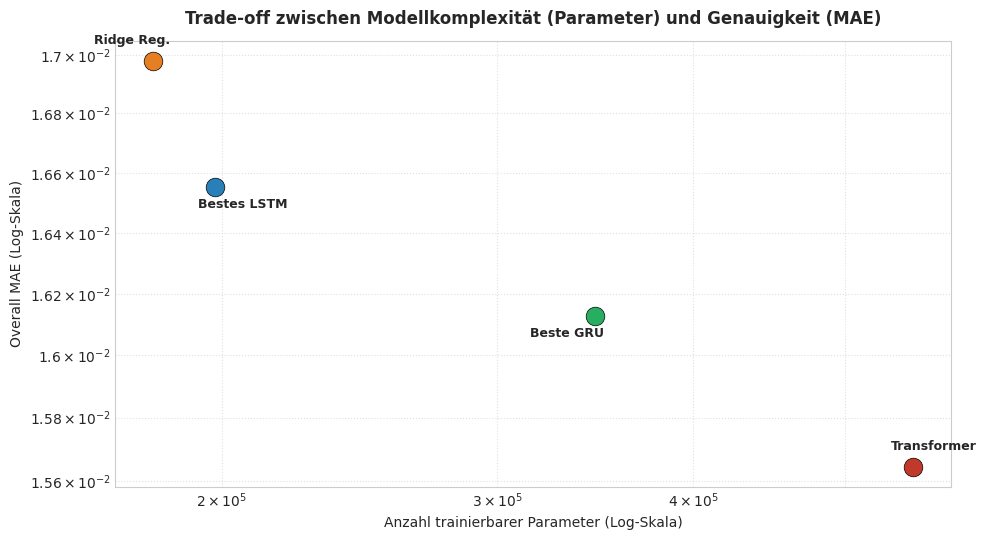

In [42]:
import matplotlib.pyplot as plt

# Aktualisierte Daten aus deinen echten Test-Set-Ergebnissen
model_stats = {
   # 'Persistence': {'params': 1, 'mae': 0.062913, 'color': '#888888', 'text_offset': (0, 10)}, # 1 statt 0 wegen Log-Skala
    'Ridge Reg.': {'params': 180912, 'mae': 0.016979, 'color': '#e67e22', 'text_offset': (-15, 12)},
    'Bestes LSTM': {'params': 198018, 'mae': 0.016552, 'color': '#2980b9', 'text_offset': (20, -15)},
    'Beste GRU': {'params': 346306, 'mae': 0.016126, 'color': '#27ae60', 'text_offset': (-20, -15)},
    'Transformer': {'params': 553026, 'mae': 0.015644, 'color': '#c0392b', 'text_offset': (15, 12)}
}

plt.figure(figsize=(10, 5.5))

for name, stats in model_stats.items():
    plt.scatter(stats['params'], stats['mae'], s=180, color=stats['color'], label=name, zorder=3, edgecolors='black', linewidth=0.5)
    plt.annotate(
        name, 
        (stats['params'], stats['mae']), 
        textcoords="offset points", 
        xytext=stats['text_offset'], 
        ha='center', 
        fontweight='bold', 
        fontsize=9
    )

plt.xscale('log') # Logarithmische Achse für Parameter-Spannweite
plt.yscale('log') # Logarithmische Achse für den Fehlerunterschied zur Baseline

plt.title("Trade-off zwischen Modellkomplexität (Parameter) und Genauigkeit (MAE)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Anzahl trainierbarer Parameter (Log-Skala)", fontsize=10)
plt.ylabel("Overall MAE (Log-Skala)", fontsize=10)
plt.grid(True, which="both", linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("plot_08_pareto_efficiency_noPers.png", dpi=300)
plt.show()

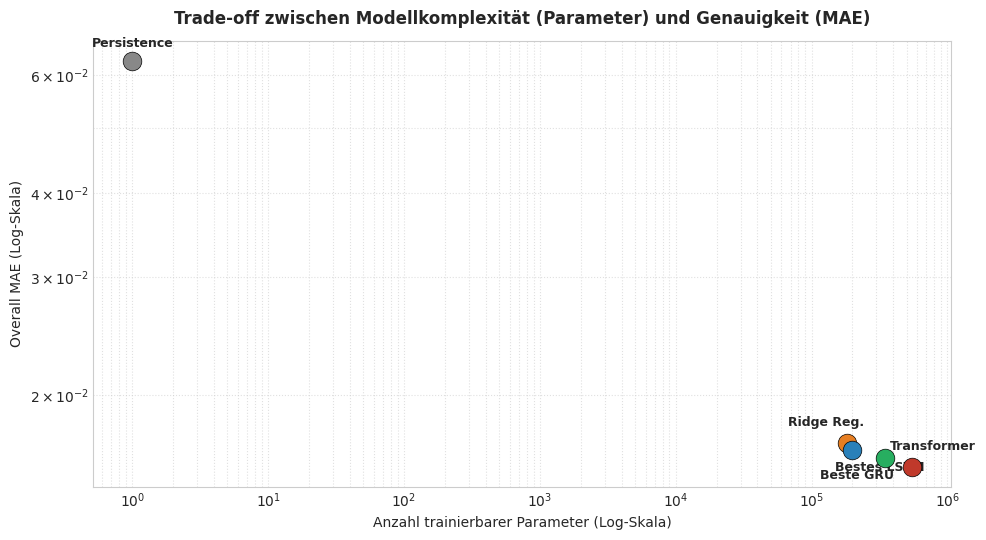

In [43]:
import matplotlib.pyplot as plt

# Aktualisierte Daten aus deinen echten Test-Set-Ergebnissen
model_stats = {
    'Persistence': {'params': 1, 'mae': 0.062913, 'color': '#888888', 'text_offset': (0, 10)}, # 1 statt 0 wegen Log-Skala
    'Ridge Reg.': {'params': 180912, 'mae': 0.016979, 'color': '#e67e22', 'text_offset': (-15, 12)},
    'Bestes LSTM': {'params': 198018, 'mae': 0.016552, 'color': '#2980b9', 'text_offset': (20, -15)},
    'Beste GRU': {'params': 346306, 'mae': 0.016126, 'color': '#27ae60', 'text_offset': (-20, -15)},
    'Transformer': {'params': 553026, 'mae': 0.015644, 'color': '#c0392b', 'text_offset': (15, 12)}
}

plt.figure(figsize=(10, 5.5))

for name, stats in model_stats.items():
    plt.scatter(stats['params'], stats['mae'], s=180, color=stats['color'], label=name, zorder=3, edgecolors='black', linewidth=0.5)
    plt.annotate(
        name, 
        (stats['params'], stats['mae']), 
        textcoords="offset points", 
        xytext=stats['text_offset'], 
        ha='center', 
        fontweight='bold', 
        fontsize=9
    )

plt.xscale('log') # Logarithmische Achse für Parameter-Spannweite
plt.yscale('log') # Logarithmische Achse für den Fehlerunterschied zur Baseline

plt.title("Trade-off zwischen Modellkomplexität (Parameter) und Genauigkeit (MAE)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Anzahl trainierbarer Parameter (Log-Skala)", fontsize=10)
plt.ylabel("Overall MAE (Log-Skala)", fontsize=10)
plt.grid(True, which="both", linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("plot_08_pareto_efficiency.png", dpi=300)
plt.show()

## Kumulierte Fehlerkurve (CDF der Fehler)

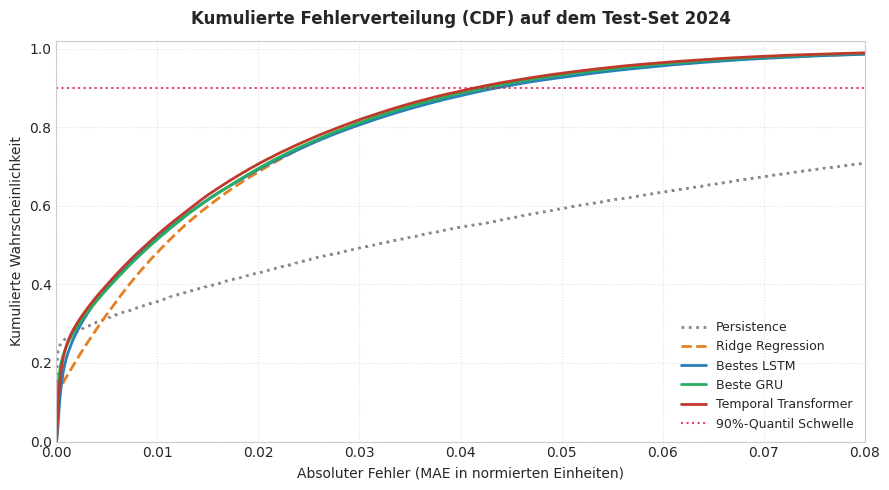

In [37]:
# ZELLE: Cumulative Distribution Function (CDF) mit reiner Matplotlib
plt.figure(figsize=(9, 5))

models_to_plot = ['Persistence', 'Ridge Regression', 'Bestes LSTM', 'Beste GRU', 'Temporal Transformer']

for name in models_to_plot:
    abs_errors = np.abs(predictions[name] - y_true_test).flatten()
    sorted_errors = np.sort(abs_errors)
    cdf = np.arange(1, len(sorted_errors) + 1) / len(sorted_errors)
    
    plt.plot(sorted_errors, cdf, label=name, color=color_map[name], linestyle=style_map[name], linewidth=2)

plt.axhline(y=0.90, color='crimson', linestyle=':', alpha=0.8, linewidth=1.5, label='90%-Quantil Schwelle')
plt.xlim(0, 0.08) # Fokus auf das relevante Intervall [0, 8%]
plt.ylim(0, 1.02)

plt.title("Kumulierte Fehlerverteilung (CDF) auf dem Test-Set 2024", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Absoluter Fehler (MAE in normierten Einheiten)", fontsize=10)
plt.ylabel("Kumulierte Wahrscheinlichkeit", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=9, loc='lower right')

plt.tight_layout()
plt.savefig("plot_09_cdf_error.png", dpi=300)
plt.show()

In [39]:
import time
import numpy as np
import pandas as pd
import torch

from baselines import evaluate_metrics

# =====================================================================
# 1. HILFSFUNKTIONEN: PARAMETERANZAHL & INFERENZZEIT BERECHNEN
# =====================================================================

def count_parameters(model):
    """Zählt die trainierbaren Parameter eines PyTorch-Modells."""
    if hasattr(model, 'parameters'):
        return sum(p.numel() for p in model.parameters() if p.requires_grad)
    elif hasattr(model, 'model') and hasattr(model.model, 'coef_'):
        # Ridge Regression: Gewichte + Biases
        return model.model.coef_.size + model.model.intercept_.size
    return 0

def measure_inference_time(model_obj, loader, is_baseline=False, num_runs=50):
    """Misst die durchschnittliche Inferenzzeit pro Batch in Millisekunden (ms)."""
    if is_baseline:
        start_time = time.time()
        for _ in range(num_runs):
            _ = model_obj.predict(loader)
        total_time = time.time() - start_time
        return (total_time / (num_runs * len(loader))) * 1000
    else:
        model_obj.model.eval()
        device = next(model_obj.model.parameters()).device
        # Einen Beispiel-Batch holen
        for x_hist, x_future, _ in loader:
            x_hist, x_future = x_hist.to(device), x_future.to(device)
            break
        
        # Warmup
        with torch.no_grad():
            for _ in range(5):
                _ = model_obj.model(x_hist, x_future)
        
        start_time = time.time()
        with torch.no_grad():
            for _ in range(num_runs):
                _ = model_obj.model(x_hist, x_future)
        total_time = time.time() - start_time
        return (total_time / num_runs) * 1000

# =====================================================================
# 2. DEFINITION DER MODELL-KONFIGURATIONEN & TITEL
# =====================================================================

model_metadata = {
    'Persistence': {
        'class': 'Persistence',
        'config': 'Naiv (24h Shift / Saisonal)',
        'pred': predictions['Persistence'],
        'params': 0,
        'inf_time': measure_inference_time(pers_model, test_loader_48, is_baseline=True)
    },
    'Ridge Regression': {
        'class': 'Ridge Regression',
        'config': 'L2-Regularisiert (alpha=1.0)',
        'pred': predictions['Ridge Regression'],
        'params': count_parameters(ridge_model),
        'inf_time': measure_inference_time(ridge_model, test_loader_48, is_baseline=True)
    },
    'Bestes LSTM': {
        'class': 'Optimiertes LSTM',
        'config': f"lookback={lstm_params['lookback_hours']}h, layers={lstm_params['num_layers']}, hid={lstm_params['hidden_dim']}, lr={lstm_params['lr']}, dr={lstm_params['dropout']}, skip={lstm_params['use_skip']}",
        'pred': predictions['Bestes LSTM'],
        'params': count_parameters(lstm_model),
        'inf_time': measure_inference_time(lstm_trainer, test_loader_24, is_baseline=False)
    },
    'Beste GRU': {
        'class': 'Optimierte GRU',
        'config': f"lookback={gru_params['lookback_hours']}h, layers={gru_params['num_layers']}, hid={gru_params['hidden_dim']}, lr={gru_params['lr']}, dr={gru_params['dropout']}, skip={gru_params['use_skip']}",
        'pred': predictions['Beste GRU'],
        'params': count_parameters(gru_model),
        'inf_time': measure_inference_time(gru_trainer, test_loader_48, is_baseline=False)
    },
    'Temporal Transformer': {
        'class': 'Temporal Transformer',
        'config': f"lookback={tf_params['lookback_hours']}h, d_model={tf_params['d_model']}, enc/dec={tf_params['num_encoder_layers']}, ff={tf_params['dim_feedforward']}, lr={tf_params['lr']}, dr={tf_params['dropout']}",
        'pred': predictions['Temporal Transformer'],
        'params': count_parameters(tf_model),
        'inf_time': measure_inference_time(tf_trainer, test_loader_48, is_baseline=False)
    }
}

# =====================================================================
# 3. TABELLE ERSTELLEN
# =====================================================================

table_rows = []

for name, meta in model_metadata.items():
    metrics = evaluate_metrics(y_true_test, meta['pred'])
    
    table_rows.append({
        'Modell-Klasse': meta['class'],
        'Konfiguration (Optimum)': meta['config'],
        'Overall MAE': f"{metrics['overall']['MAE']:.6f}",
        'Overall RMSE': f"{metrics['overall']['RMSE']:.6f}",
        'Solar MAE': f"{metrics['solar']['MAE']:.6f}",
        'Wind MAE': f"{metrics['wind']['MAE']:.6f}",
        'Parameter': f"{meta['params']:,}",
        'Inferenzzeit (ms)': f"{meta['inf_time']:.2f}"
    })

df_final_benchmark = pd.DataFrame(table_rows)

print("\n=== FINALE BENCHMARK-TABELLE (TEST-SET 2024) ===")
print(df_final_benchmark.to_string(index=False))

# =====================================================================
# 4. CSV-OUTPUT FÜR EXCEL (SEMIKOLON-GETRENNT MIT DEZIMAL-KOMMA)
# =====================================================================

print("\n\n=== CSV-CODE FÜR EXCEL (Einfach kopieren und einfügen) ===")
csv_df = df_final_benchmark.copy()

# Punkte durch Kommas ersetzen für deutsches Excel
for col in ['Overall MAE', 'Overall RMSE', 'Solar MAE', 'Wind MAE', 'Inferenzzeit (ms)']:
    csv_df[col] = csv_df[col].str.replace('.', ',', regex=False)

print(csv_df.to_csv(sep=';', index=False))


=== FINALE BENCHMARK-TABELLE (TEST-SET 2024) ===
       Modell-Klasse                                         Konfiguration (Optimum) Overall MAE Overall RMSE Solar MAE Wind MAE Parameter Inferenzzeit (ms)
         Persistence                                     Naiv (24h Shift / Saisonal)    0.062913     0.102966  0.021435 0.104398         0              2.05
    Ridge Regression                                    L2-Regularisiert (alpha=1.0)    0.016979     0.025578  0.010240 0.023719   180,912              3.43
    Optimiertes LSTM   lookback=24h, layers=1, hid=128, lr=0.0005, dr=0.2, skip=True    0.016552     0.026071  0.010633 0.022471   198,018              4.19
      Optimierte GRU  lookback=48h, layers=2, hid=128, lr=0.0005, dr=0.2, skip=False    0.016126     0.025140  0.011055 0.021198   346,306             23.95
Temporal Transformer lookback=48h, d_model=128, enc/dec=2, ff=128, lr=0.0005, dr=0.1    0.015644     0.024652  0.009984 0.021305   553,026             19.65


=== CS